# 2 · Style files  *(20 min)*

So far every plot was styled by hand, inside its cell. Plan for this notebook:

1. 🎛 Style three different plots by hand.
2. Create a **style file** with one cell: a text file with your settings.
3. 🎛 Edit that file, save it, re-run: every plot changes, without touching the plot code.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

import neurodata

oris, responses = neurodata.orientation_tuning(n_neurons=3)
mean = responses.mean(axis=2)
trials = neurodata.spike_trains(n_trials=30)
isi_ms = np.concatenate([np.diff(trial) for trial in trials]) * 1000
sem = responses.std(axis=2) / np.sqrt(responses.shape[2])
drug_trials = neurodata.spike_trains(n_trials=30, peak_rate=30, sustained_rate=12, seed=1)
rates_control = [len(trial) / 2 for trial in trials]   # spikes per 2-s trial -> Hz
rates_drug = [len(trial) / 2 for trial in drug_trials]
baseline, drug = neurodata.drug_experiment(n_animals=10)
t_ca, dff, stim_times = neurodata.calcium_imaging()

## 1. 🎛 Style by hand

Change the values at the top of each cell and re-run it. Note the ones you like.

**Tuning curves**: lines with markers and a legend.

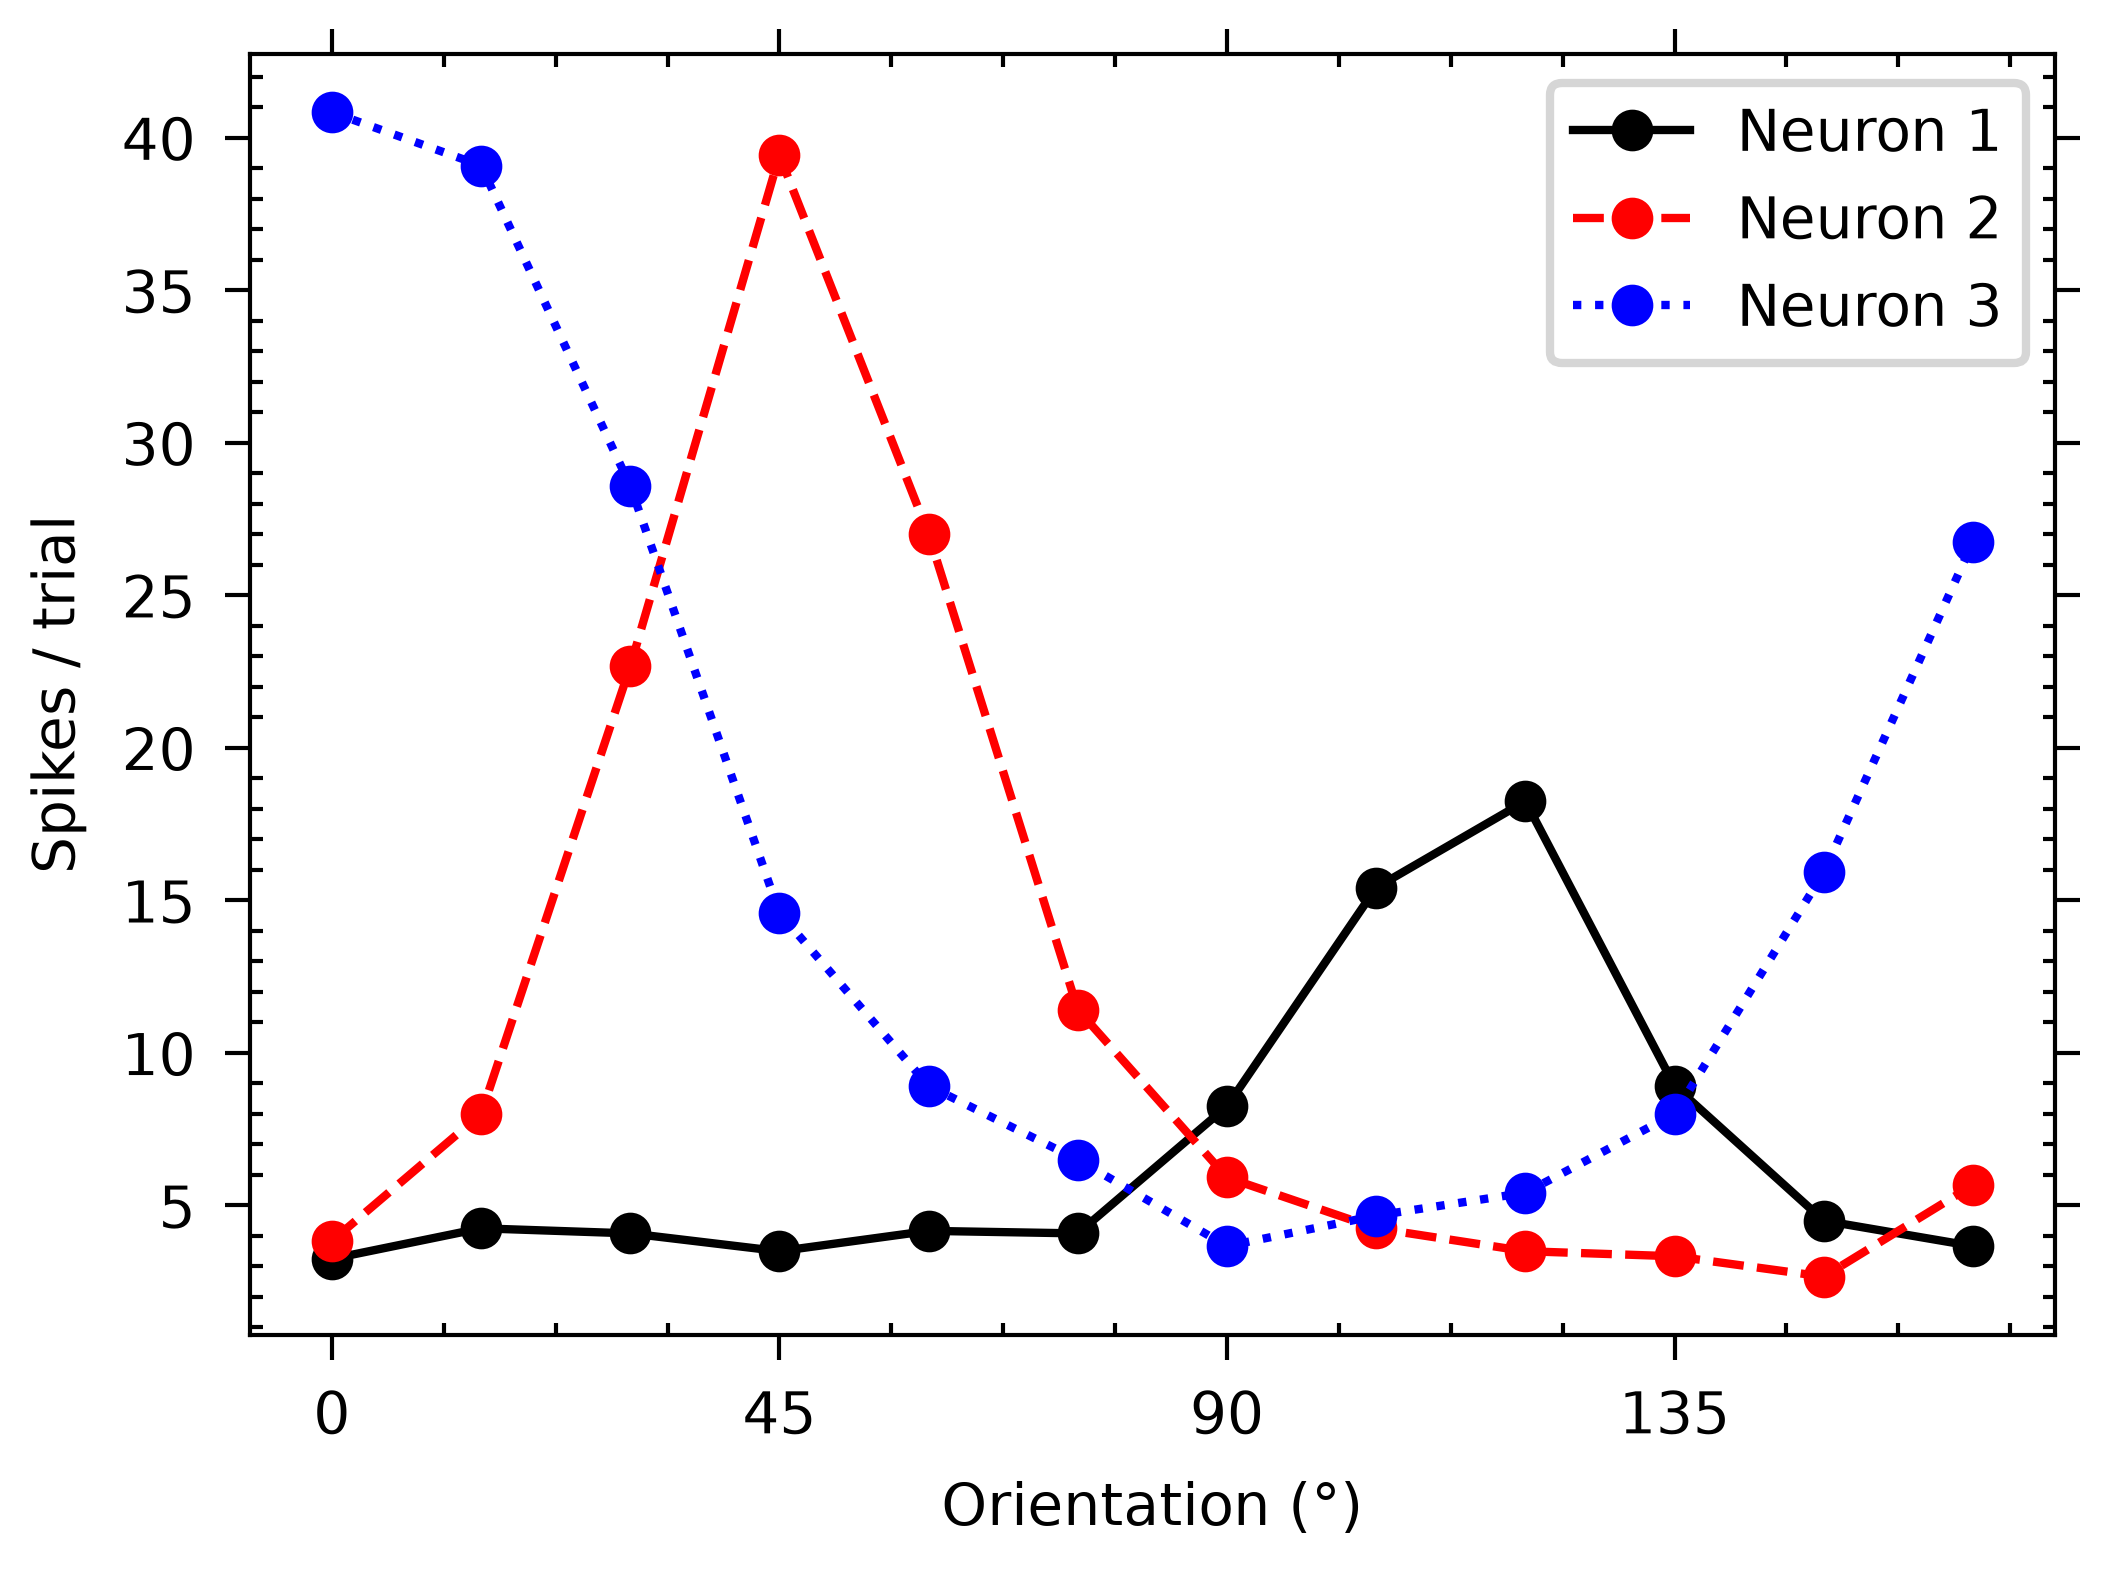

In [14]:
marker = "o"          # "o", "s", "^", "D", or "" for none
marker_size = 4       # try 2 to 10
line_width = 1.0      # try 0.25 to 3
ticks = "out"         # "out" or "in"
legend_frame = True   # True or False

fig, ax = plt.subplots(figsize=(3.5, 2.6))
for i in range(3):
    ax.plot(oris, mean[i], marker=marker, markersize=marker_size, linewidth=line_width, label=f"Neuron {i + 1}")
ax.set(xlabel="Orientation (°)", ylabel="Spikes / trial", xticks=[0, 45, 90, 135])
ax.tick_params(direction=ticks)
ax.legend(frameon=legend_frame)
plt.show()

**Histogram**: inter-spike intervals from 30 trials.

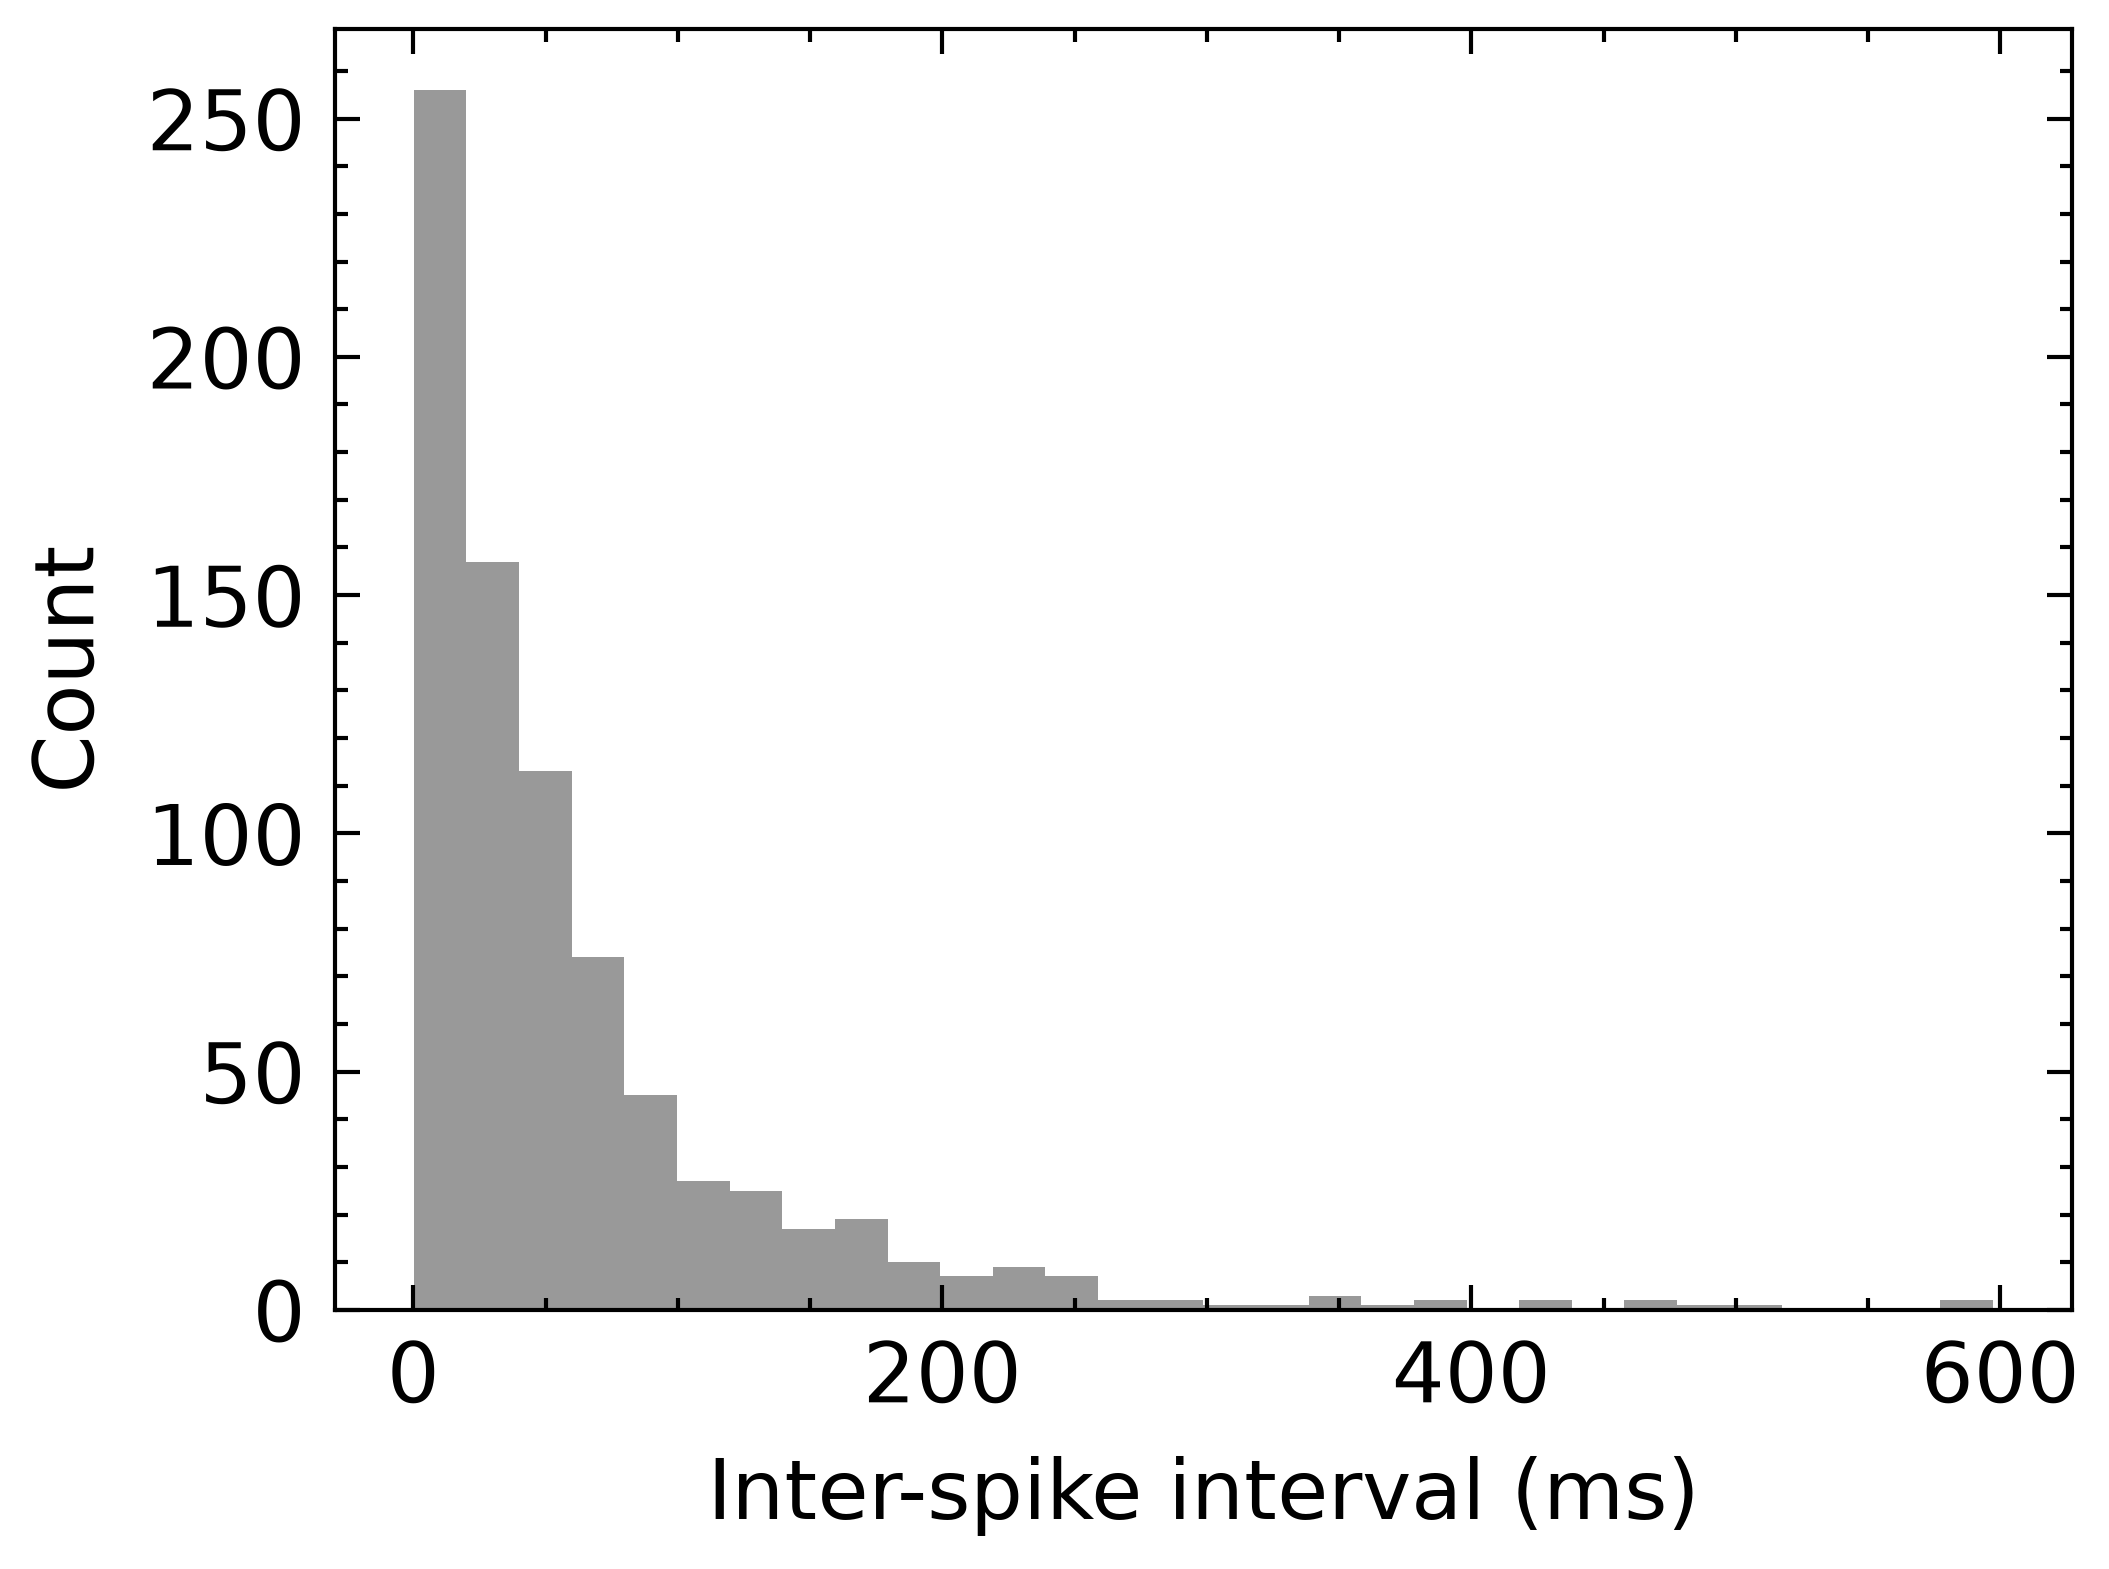

In [15]:
bar_color = "0.6"      # grey: "0.0" (black) to "1.0" (white), or a color like "tab:blue"
edge_color = "none"    # outline of the bars: "none", "black", "white"
font_size = 10         # try 5 to 16
box = True             # True or False: top and right frame lines

fig, ax = plt.subplots(figsize=(3.5, 2.6))
ax.hist(isi_ms, bins=30, color=bar_color, edgecolor=edge_color)
ax.set_xlabel("Inter-spike interval (ms)", fontsize=font_size)
ax.set_ylabel("Count", fontsize=font_size)
ax.tick_params(labelsize=font_size)
ax.spines[["top", "right"]].set_visible(box)
plt.show()

**Scatter**: each point is one animal. Points below the grey diagonal fired less with the drug.

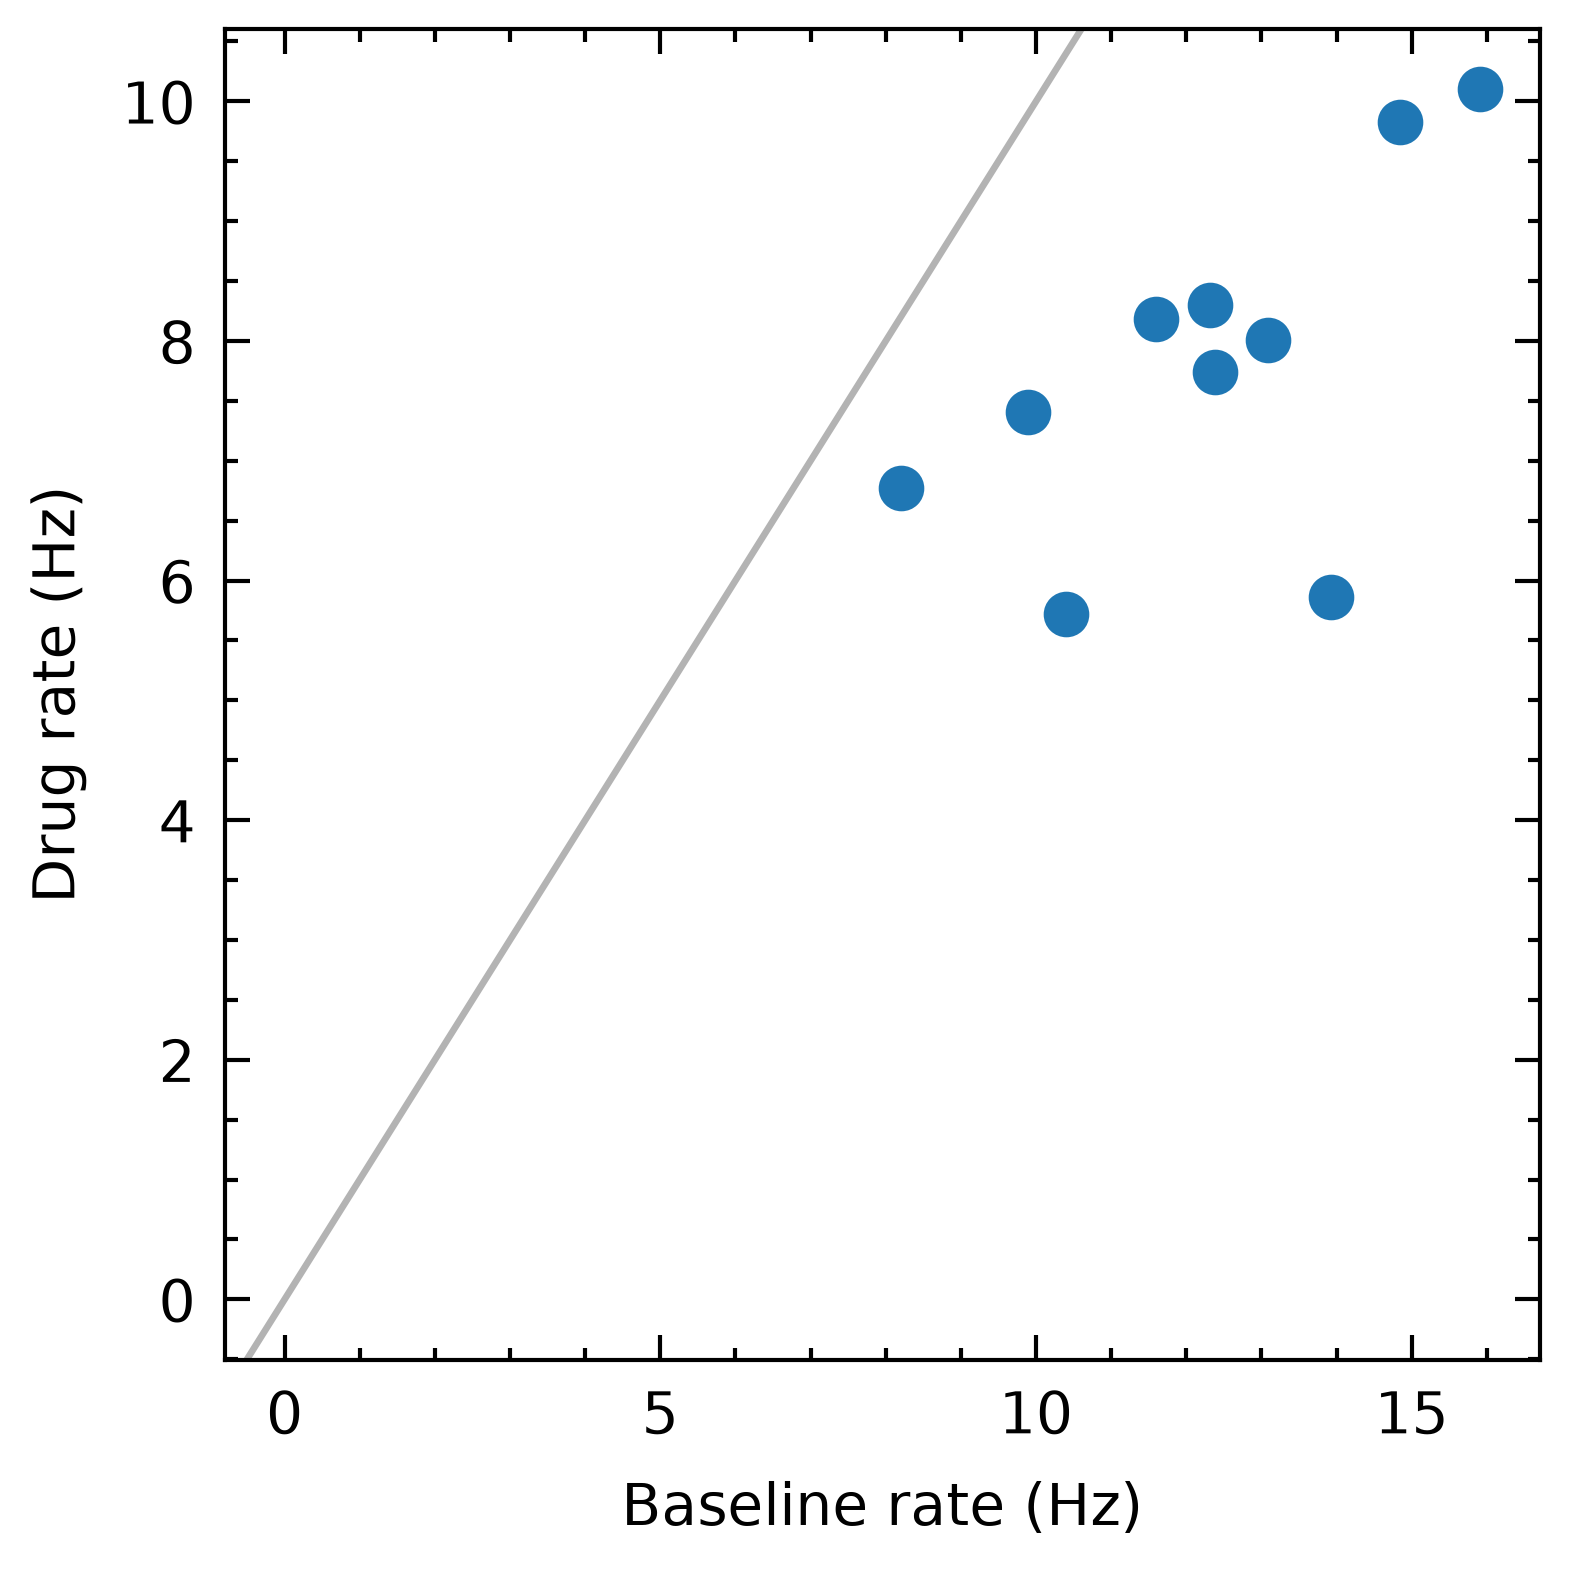

In [16]:
point_color = "tab:blue"   # any color name, or hex like "#D55E00"
point_size = 20            # area in points², try 5 to 100
grid = False               # True or False

fig, ax = plt.subplots(figsize=(2.6, 2.6))
ax.scatter(baseline, drug, s=point_size, color=point_color)
ax.axline((0, 0), slope=1, color="0.7", linewidth=0.8)   # the diagonal: "no change"
ax.set(xlabel="Baseline rate (Hz)", ylabel="Drug rate (Hz)")
ax.grid(grid)
plt.show()

Every plot needed its own settings, and in the next notebook you would type them all again.
A **style file** sets them once, for every plot. Each argument has a name in the style file:

| In the plot cell | In the style file |
|---|---|
| `figsize=(3.5, 2.6)` | `figure.figsize: 3.5, 2.6` |
| `fontsize=10`, `labelsize=10` | `font.size: 10` |
| `linewidth=1.0` | `lines.linewidth: 1.0` |
| `markersize=4` | `lines.markersize: 4` (also sets the scatter point size) |
| `ax.tick_params(direction="out")` | `xtick.direction: out` and `ytick.direction: out` |
| `ax.spines[["top", "right"]].set_visible(False)` | `axes.spines.top: False` and `axes.spines.right: False` |
| `ax.legend(frameon=False)` | `legend.frameon: False` |
| `ax.grid(True)` | `axes.grid: True` |
| `edgecolor="black"` on bars | `patch.force_edgecolor: True` |
| `color=...` for line 1, 2, 3 | `axes.prop_cycle: cycler('color', ['0072B2', 'D55E00', '009E73'])` |

## 2. Create your style file

Run this cell **once**. `%%writefile` saves the cell's text into the file `my_style.mplstyle`, next to this
notebook. A style file has one `name: value` per line; `#` starts a comment.

In [17]:
%%writefile my_style.mplstyle
# Set color cycle: blue, green, yellow, red, violet, gray
# axes.prop_cycle : cycler('color', ['0C5DA5', '00B945', 'FF9500', 'FF2C00', '845B97', '474747', '9e9e9e'])
axes.prop_cycle : (cycler('color', ['k', 'r', 'b', 'g']) + cycler('ls', ['-', '--', ':', '-.']))
# axes.prop_cycle : cycler('color', ['4165c0', 'e770a2', '5ac3be', '696969', 'f79a1e', 'ba7dcd'])
# axes.prop_cycle : cycler('color', ['004488', 'DDAA33', 'BB5566'])
# axes.prop_cycle : cycler('color', ['EE7733', '0077BB', '33BBEE', 'EE3377', 'CC3311', '009988', 'BBBBBB'])
# axes.prop_cycle : (cycler('color', ['k', 'r', 'b', 'g']) + cycler('ls', ['-', '--', ':', '-.']) + cycler('marker', ['o', 's', '^', 'D']))

# Set default figure size

figure.figsize : 3.5, 2.625  
savefig.dpi : 300
pdf.fonttype : 42
ps.fonttype : 42
svg.fonttype : none
figure.dpi : 600                    

# Set x axis
# direction of ticks
xtick.direction : in # in | out
# size of the ticks
xtick.major.size : 3 
# width of the ticks
xtick.major.width : 0.5
# size of minor ticks
xtick.minor.size : 1.5
# minor ticks width
xtick.minor.width : 0.5
# should minor ticks be visible
xtick.minor.visible : True
# draws tick marks along the top edge
xtick.top : True

# Set y axis
ytick.direction : in
ytick.major.size : 3
ytick.major.width : 0.5
ytick.minor.size : 1.5
ytick.minor.width : 0.5
ytick.minor.visible : True
ytick.right : True

# Set line widths
# axes lines
axes.linewidth : 0.5 # default 0.8
# grid lines behind the data if using grid
grid.linewidth : 0.5
# the data lines
lines.linewidth : 1.

# legend
grid.linewidth : 0.5
legend.frameon : False

# Always save as 'tight'
savefig.bbox : tight
savefig.pad_inches : 0.05

# Font sizes (these are for Nature)
axes.labelsize: 7
xtick.labelsize: 7
ytick.labelsize: 7
legend.fontsize: 7
font.size: 7 

# Use serif fonts
# font.serif : Times
font.family : sans-serif   # serif | sans-serif | monospace | cursive | fantasy
mathtext.fontset : dejavuserif

# Grid lines behind the data 
axes.grid : False 

# Box plots 
boxplot.notch : False                  # True | False
boxplot.showmeans : False              # True | False
boxplot.showfliers : False              # True | False: show outliers
boxplot.patchartist : False            # True | False: True gives filled boxes
boxplot.flierprops.marker : o          # outlier marker: o | x | + | . | d | s
boxplot.medianprops.color : C1         # C1 = 2nd color of the color cycle; or any color


# Scatter, bars, histograms 
scatter.marker : o                     # o | s | ^ | v | d | D | x | + | * | .
scatter.edgecolors : none              # face (outline = fill color) | none | any color
patch.linewidth : 1.0                  # outline width of bars, boxes, ... (pt)
patch.edgecolor : black                # outline color, only drawn if force_edgecolor is True
patch.force_edgecolor : False          # True | False: outlines on histogram/bar plots
errorbar.capsize : 0                   # length of the error bar caps, pt (0 = no caps)

figure.constrained_layout.use : True

image.aspect : auto
image.cmap : viridis


Overwriting my_style.mplstyle


The same plots again plus a few new ones, with **no styling in the code**: everything comes from the style file.

In [18]:
def show_plots():
    # Lines with markers
    fig, ax = plt.subplots()
    for i in range(3):
        ax.plot(oris, mean[i], marker="o", label=f"Neuron {i + 1}")
    ax.set(xlabel="Orientation (°)", ylabel="Spikes / trial", xticks=[0, 45, 90, 135])
    ax.legend()

    # Error bars: mean ± SEM
    fig, ax = plt.subplots()
    for i in range(3):
        ax.errorbar(oris, mean[i], yerr=sem[i], label=f"Neuron {i + 1}")
    ax.set(xlabel="Orientation (°)", ylabel="Spikes / trial", xticks=[0, 45, 90, 135])
    ax.legend()

    # Scatter
    fig, ax = plt.subplots()
    ax.scatter(baseline, drug)
    ax.axline((0, 0), slope=1, color="0.7")
    ax.set(xlabel="Baseline rate (Hz)", ylabel="Drug rate (Hz)")

    # Histogram
    fig, ax = plt.subplots()
    ax.hist(isi_ms, bins=30)
    ax.set(xlabel="Inter-spike interval (ms)", ylabel="Count")

    # Two histograms side by side (number of bins from the style: hist.bins)
    fig, ax = plt.subplots()
    ax.hist([rates_control, rates_drug], label=["Control", "Drug"])
    ax.set(xlabel="Firing rate (Hz)", ylabel="Trials")
    ax.legend()

    # Box plot
    fig, ax = plt.subplots()
    ax.boxplot([baseline, drug])
    ax.set_xticks([1, 2], ["Baseline", "Drug"])
    ax.set(ylabel="Firing rate (Hz)")

    # Heatmap: calcium imaging, neurons x time
    fig, ax = plt.subplots()
    im = ax.imshow(dff, extent=[0, t_ca[-1], len(dff), 0])
    fig.colorbar(im, ax=ax, label=r"$\Delta F/F$")
    ax.set(xlabel="Time (s)", ylabel="Neuron")
    plt.show()

## 3. 🎛 Edit the file

1. Run the cell below.
2. Open `my_style.mplstyle`: double-click it in the file browser on the left.
3. Change a value, e.g. `font.size: 7` → `font.size: 12`, or `axes.spines.top: False` → `True`.
4. Save the file (**Ctrl+S**) and re-run the cell below.

Don't re-run the `%%writefile` cell: it would overwrite your changes.
`"default"` resets everything first, so a line you delete from the file really goes away.

Duplicate key in file 'my_style.mplstyle', line 52 ('grid.linewidth : 0.5')


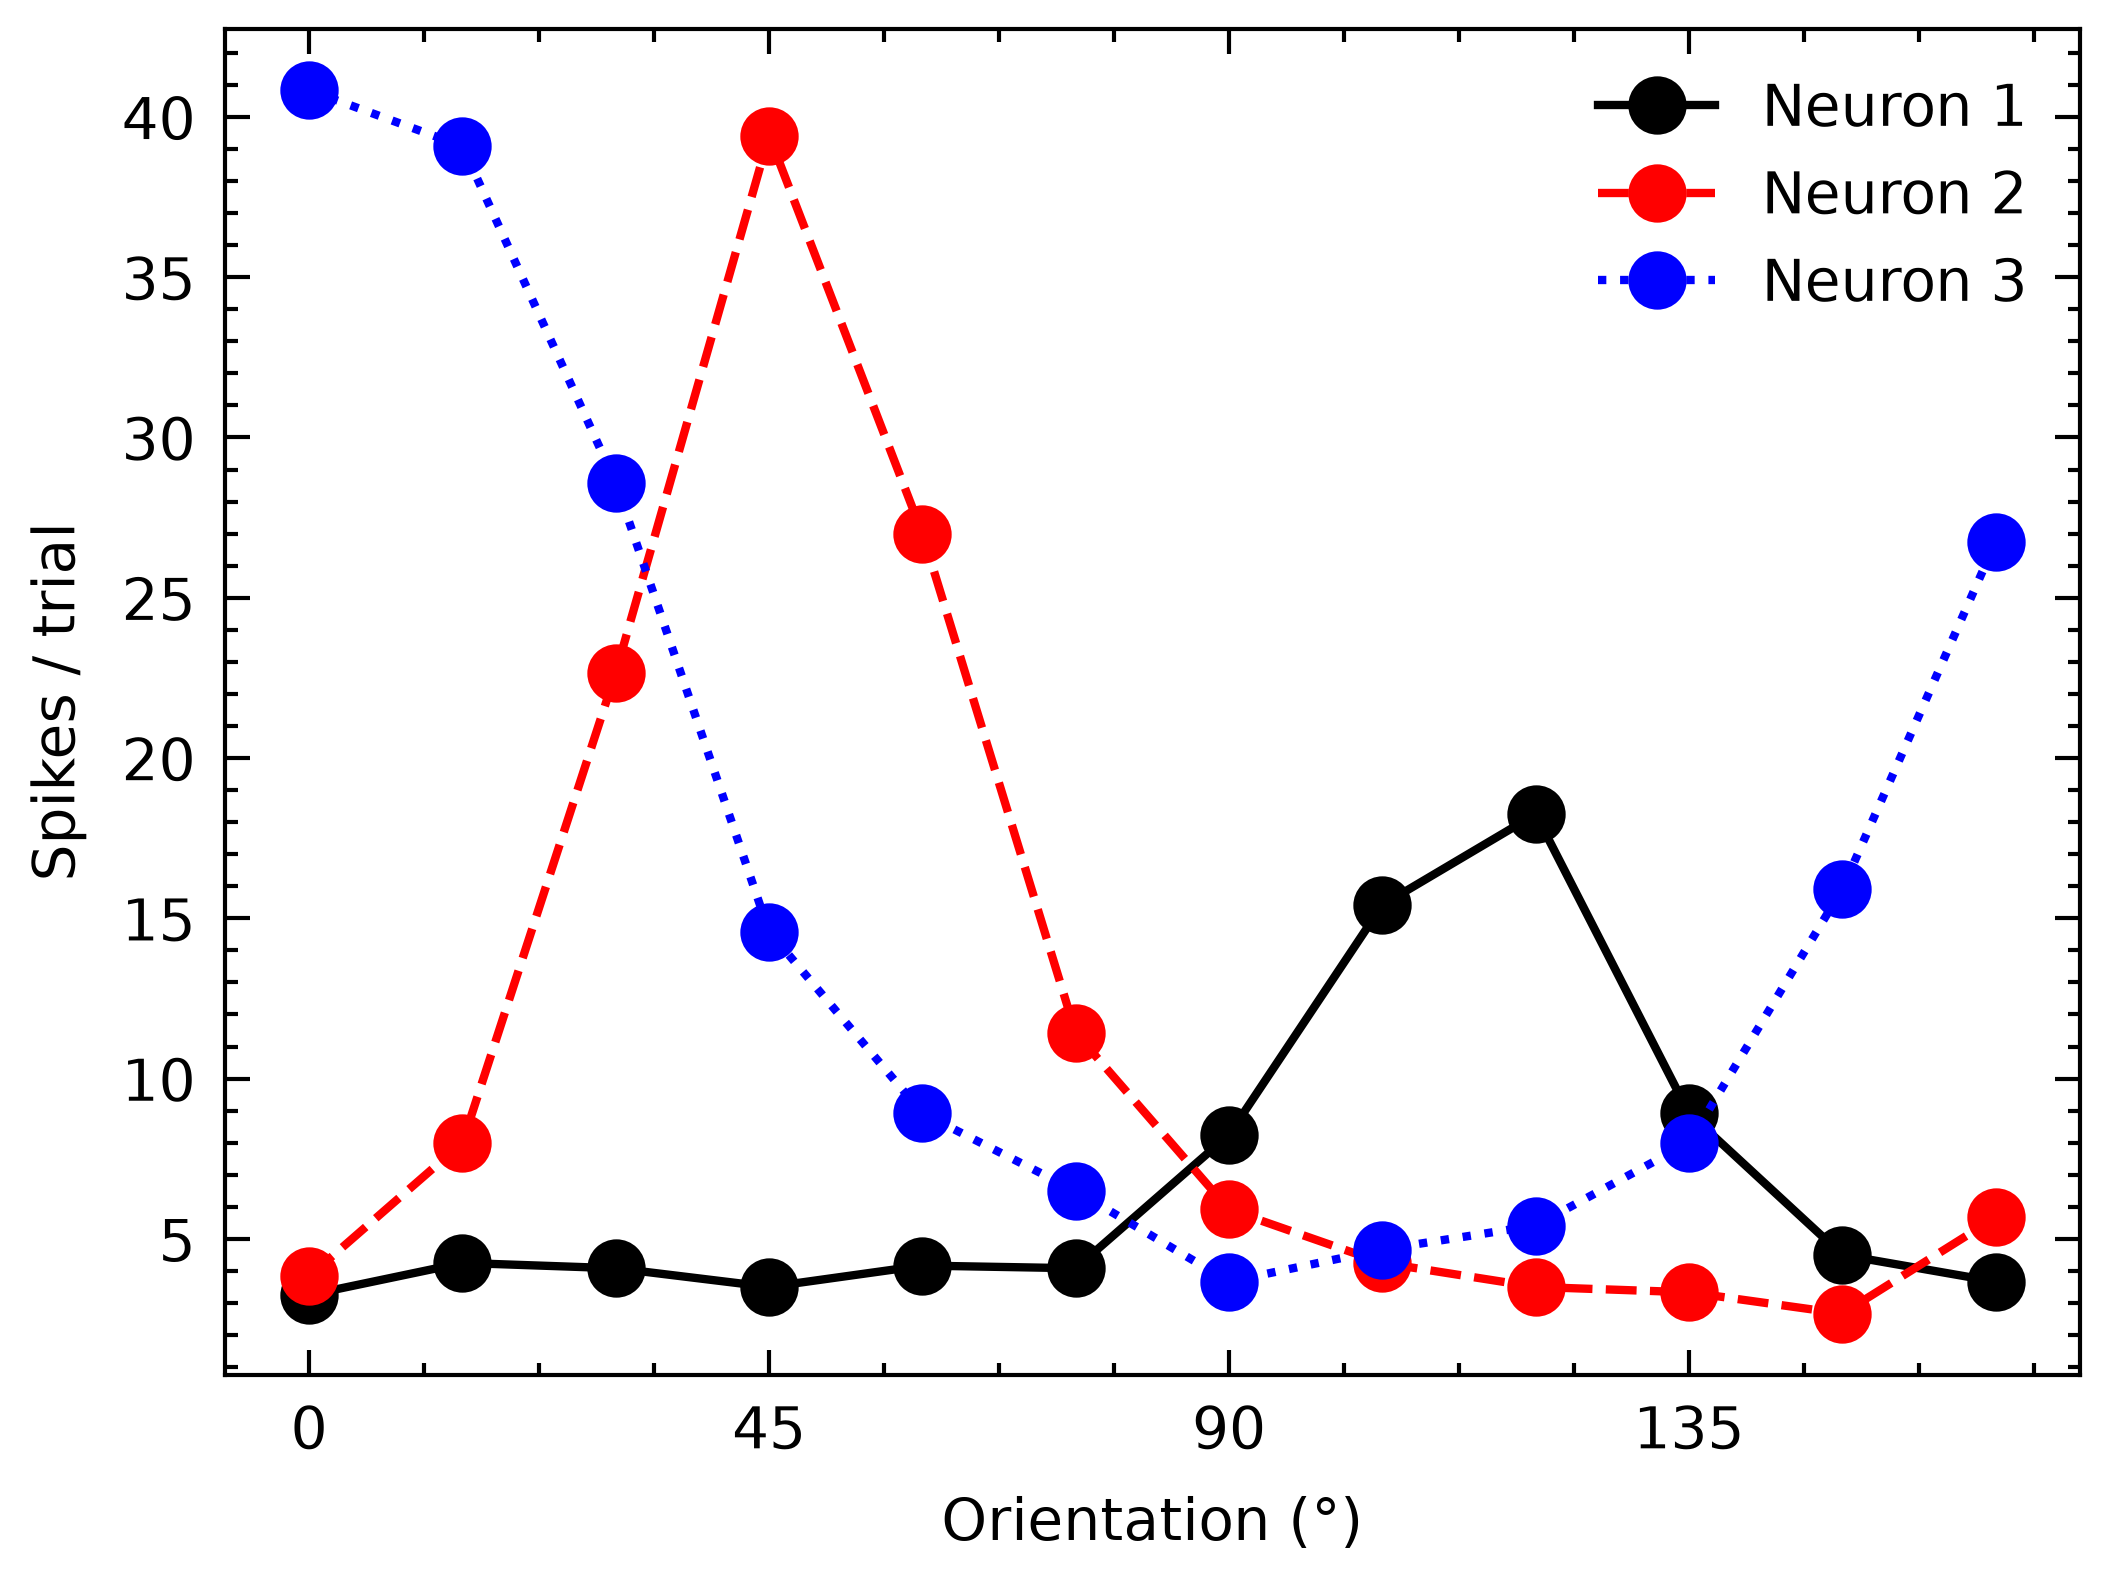

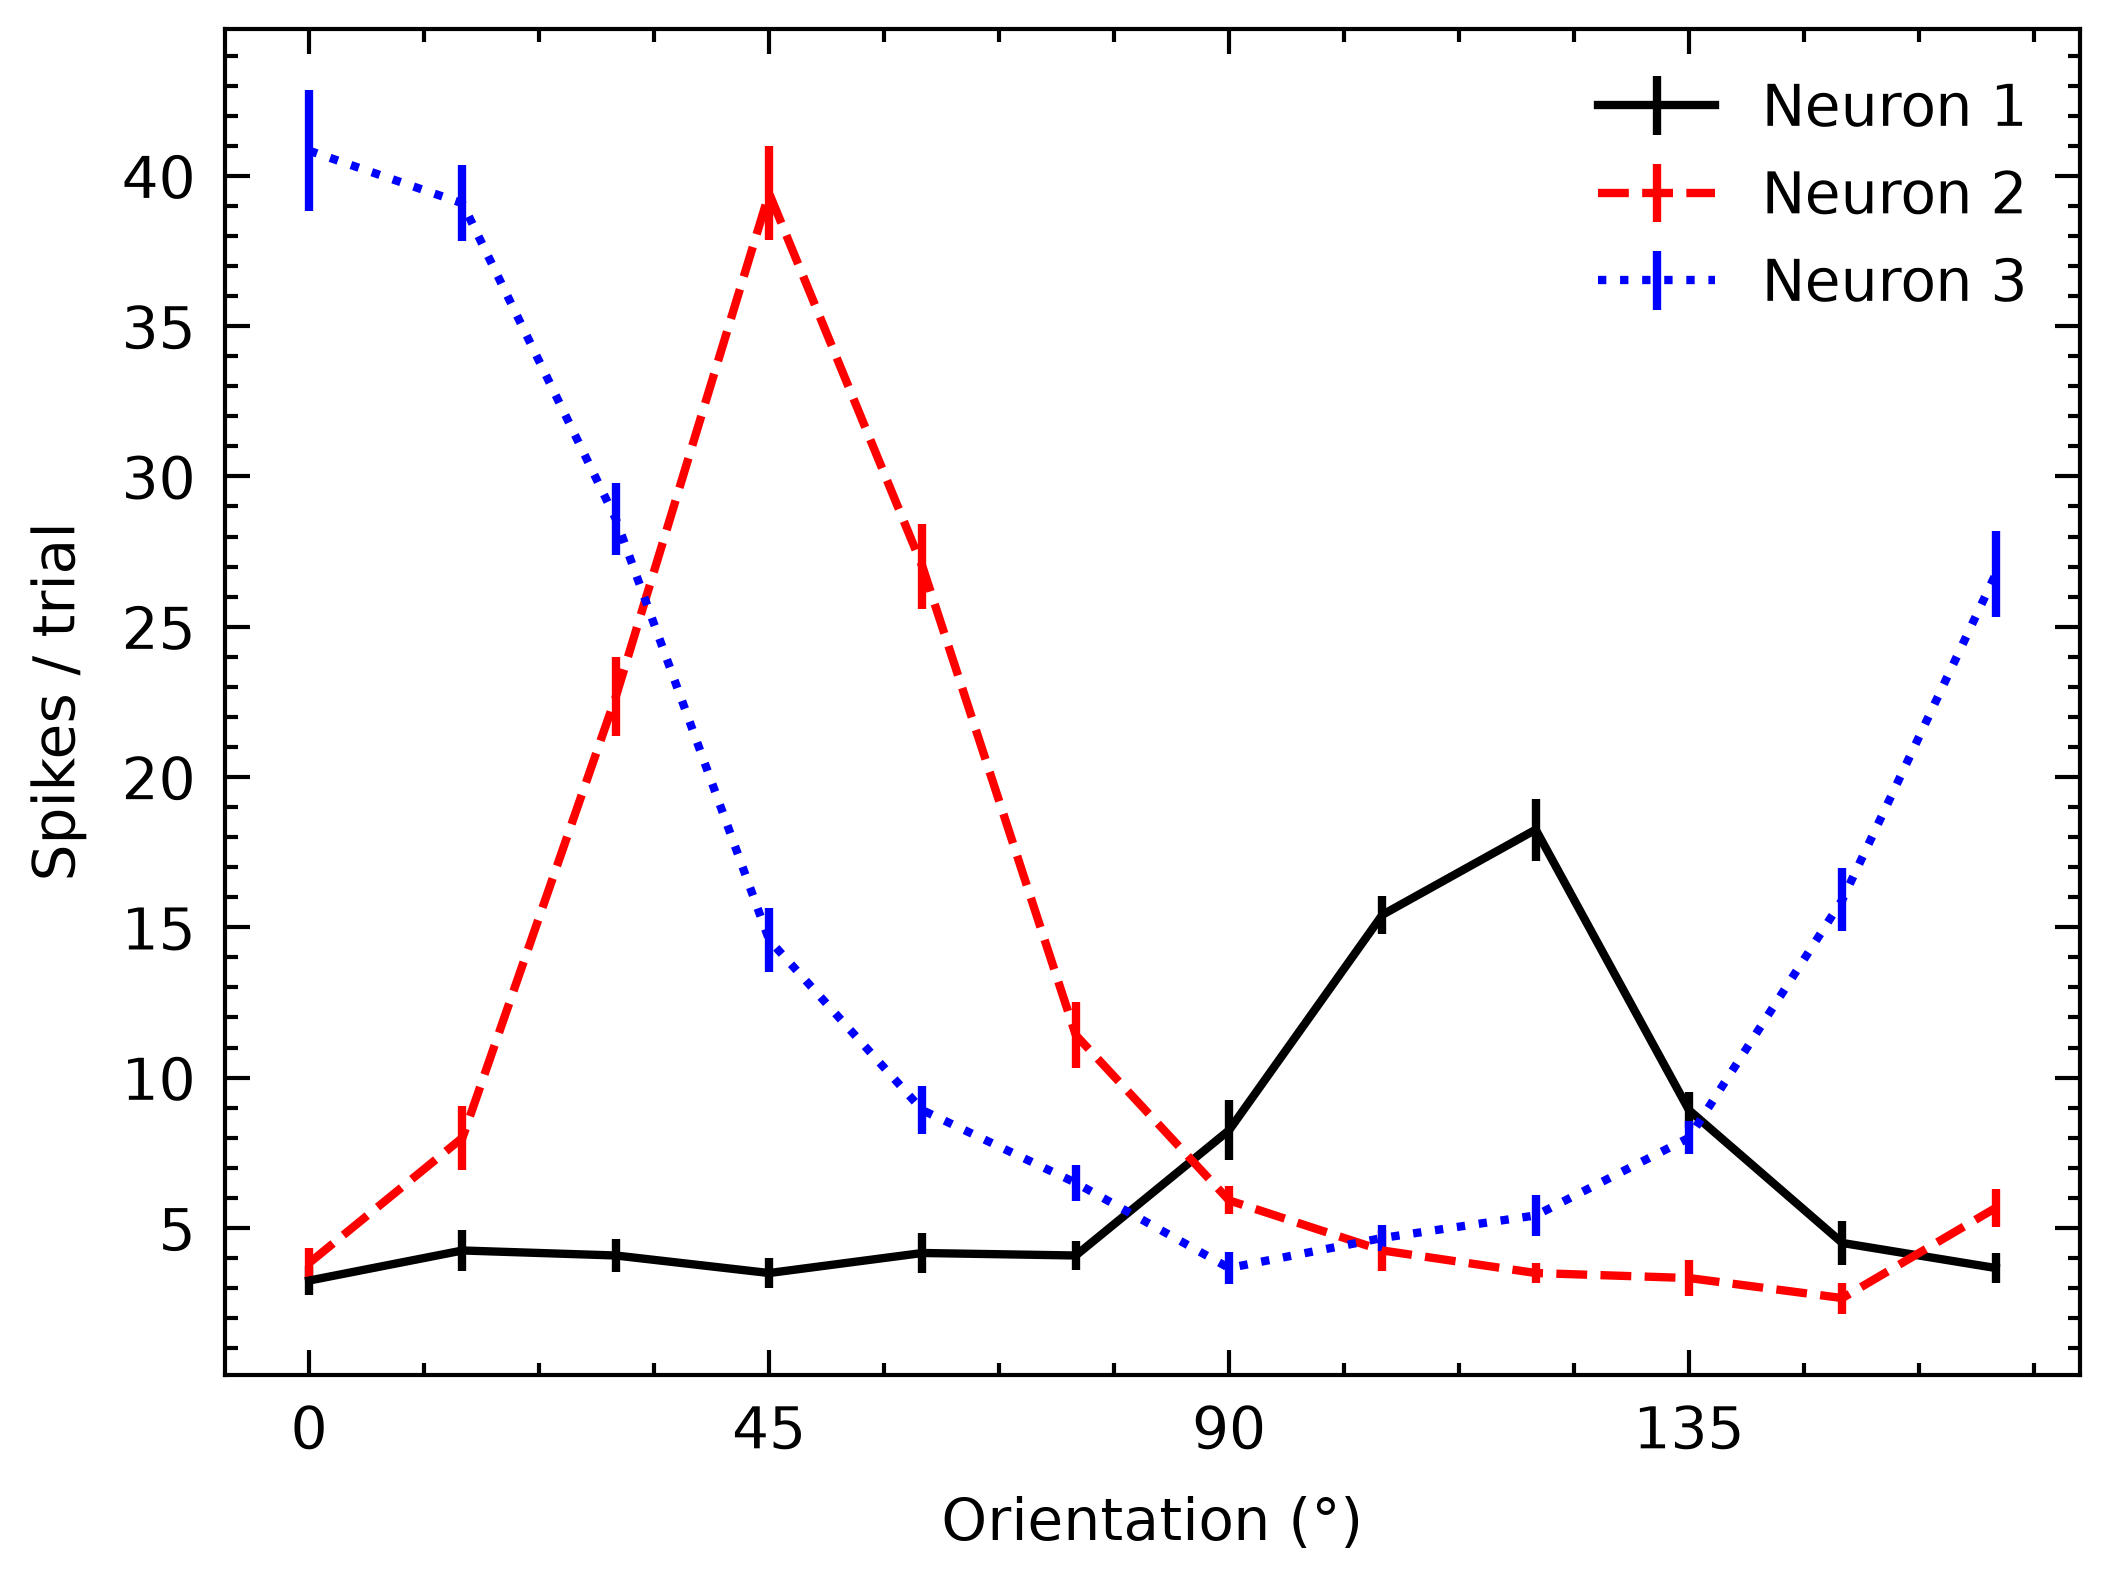

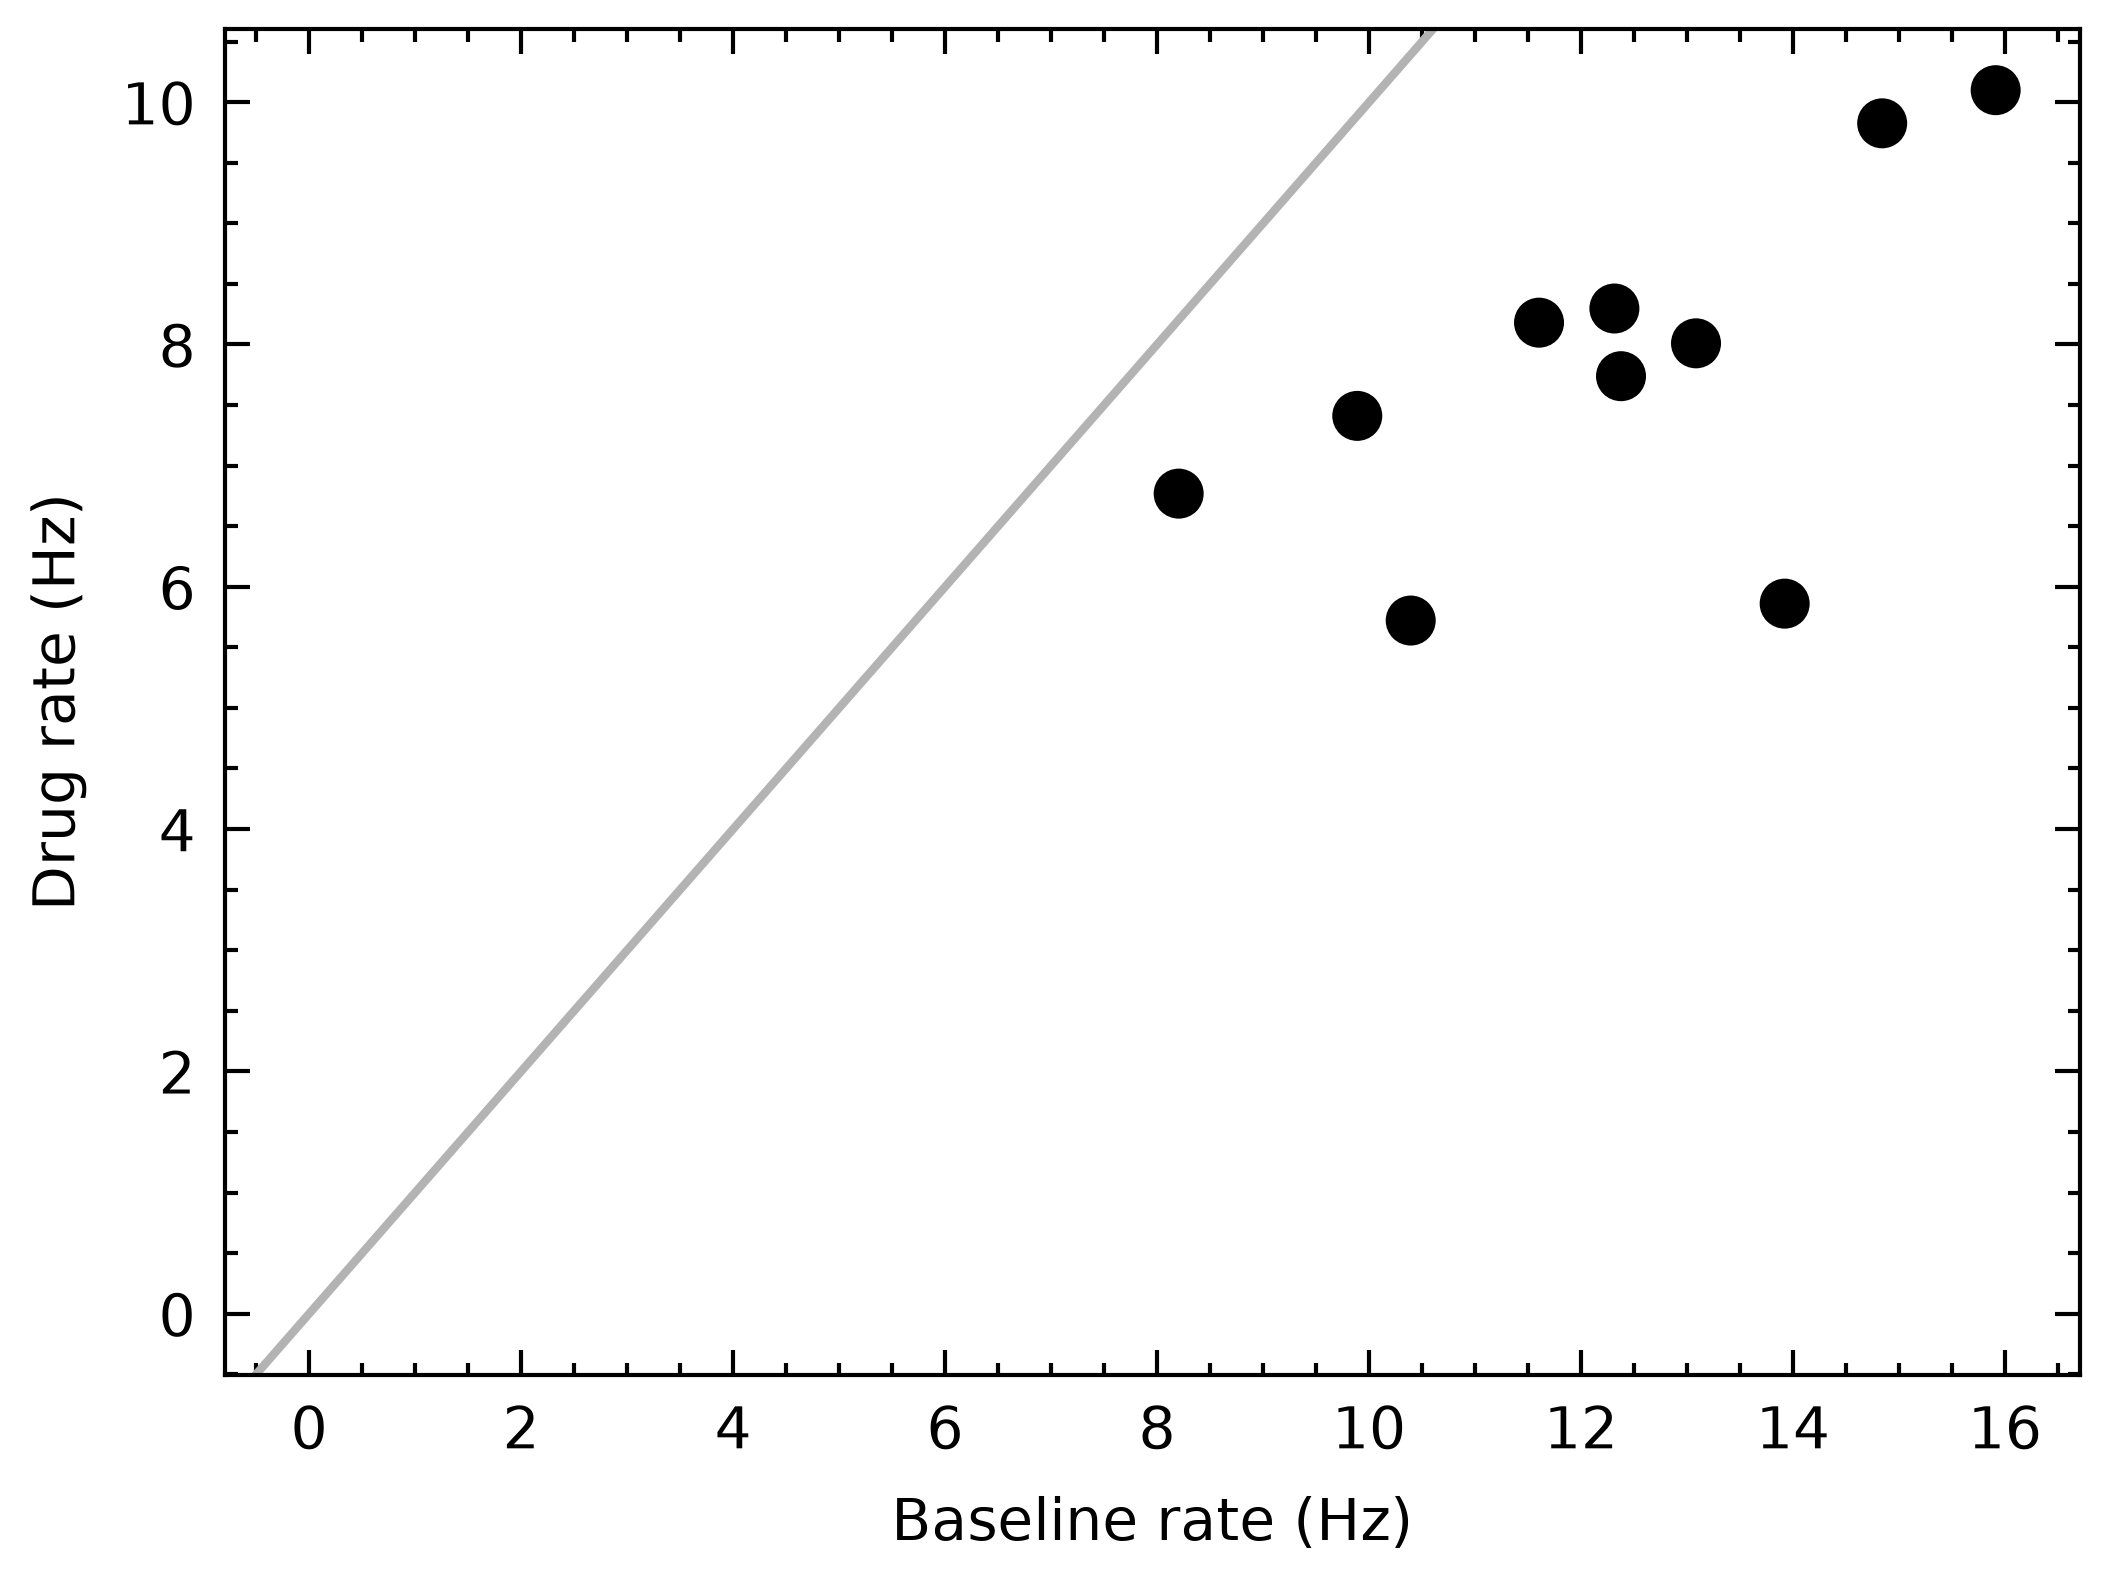

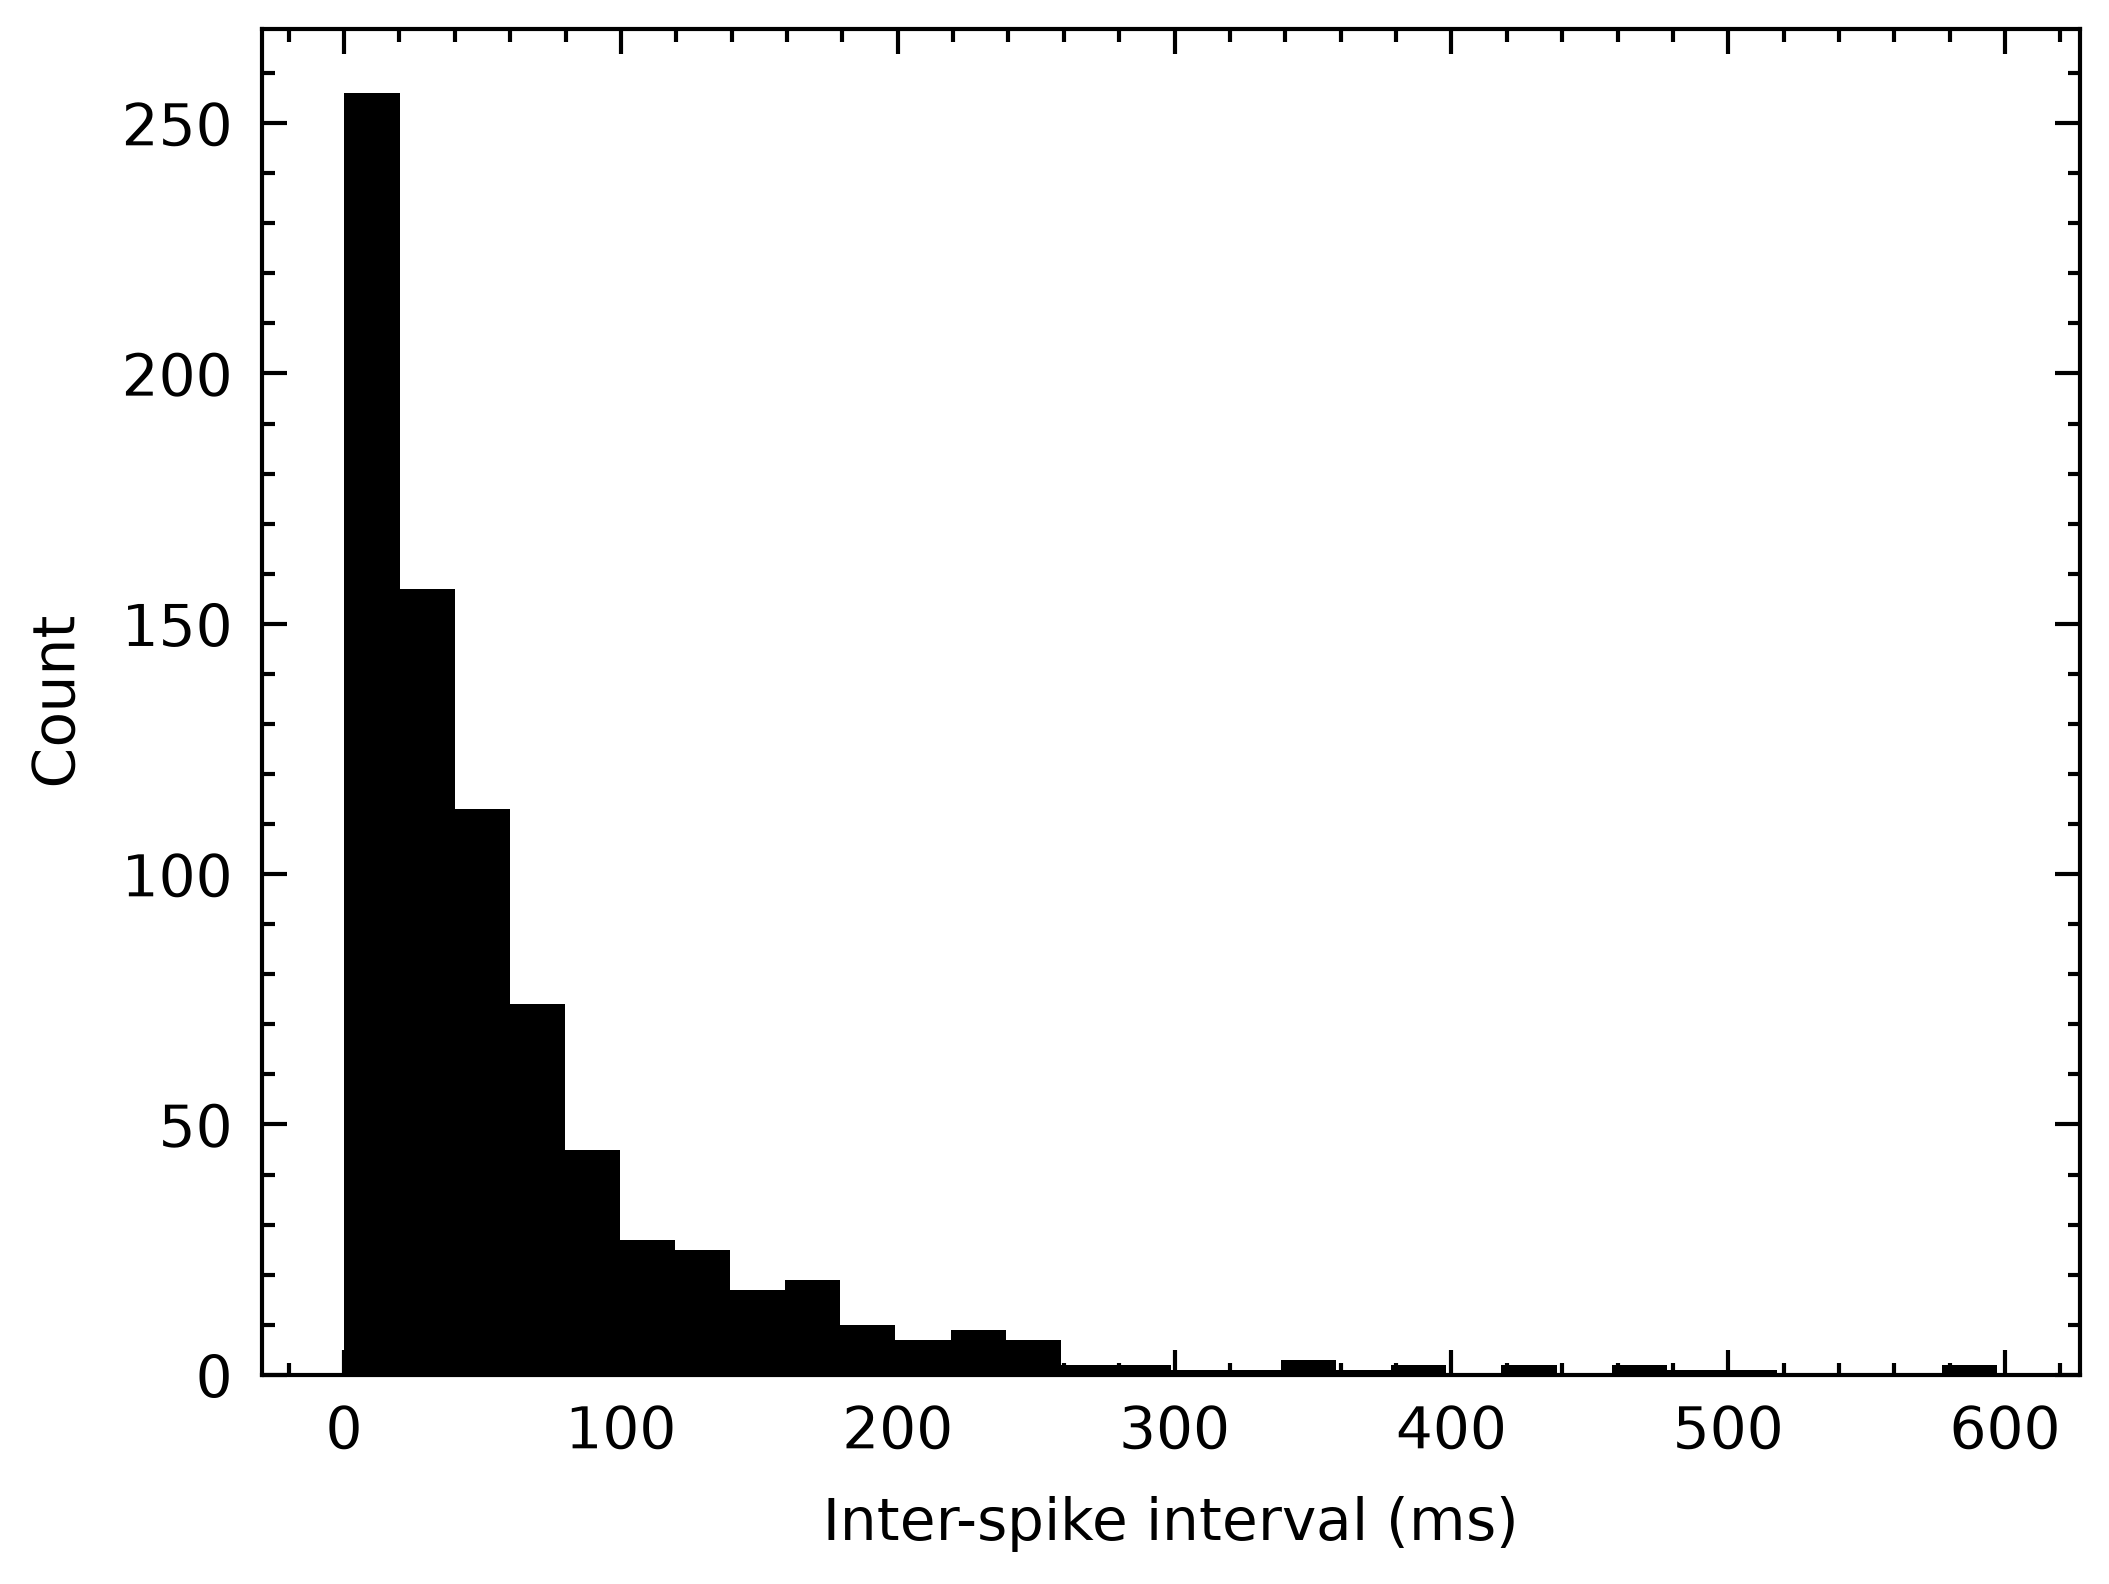

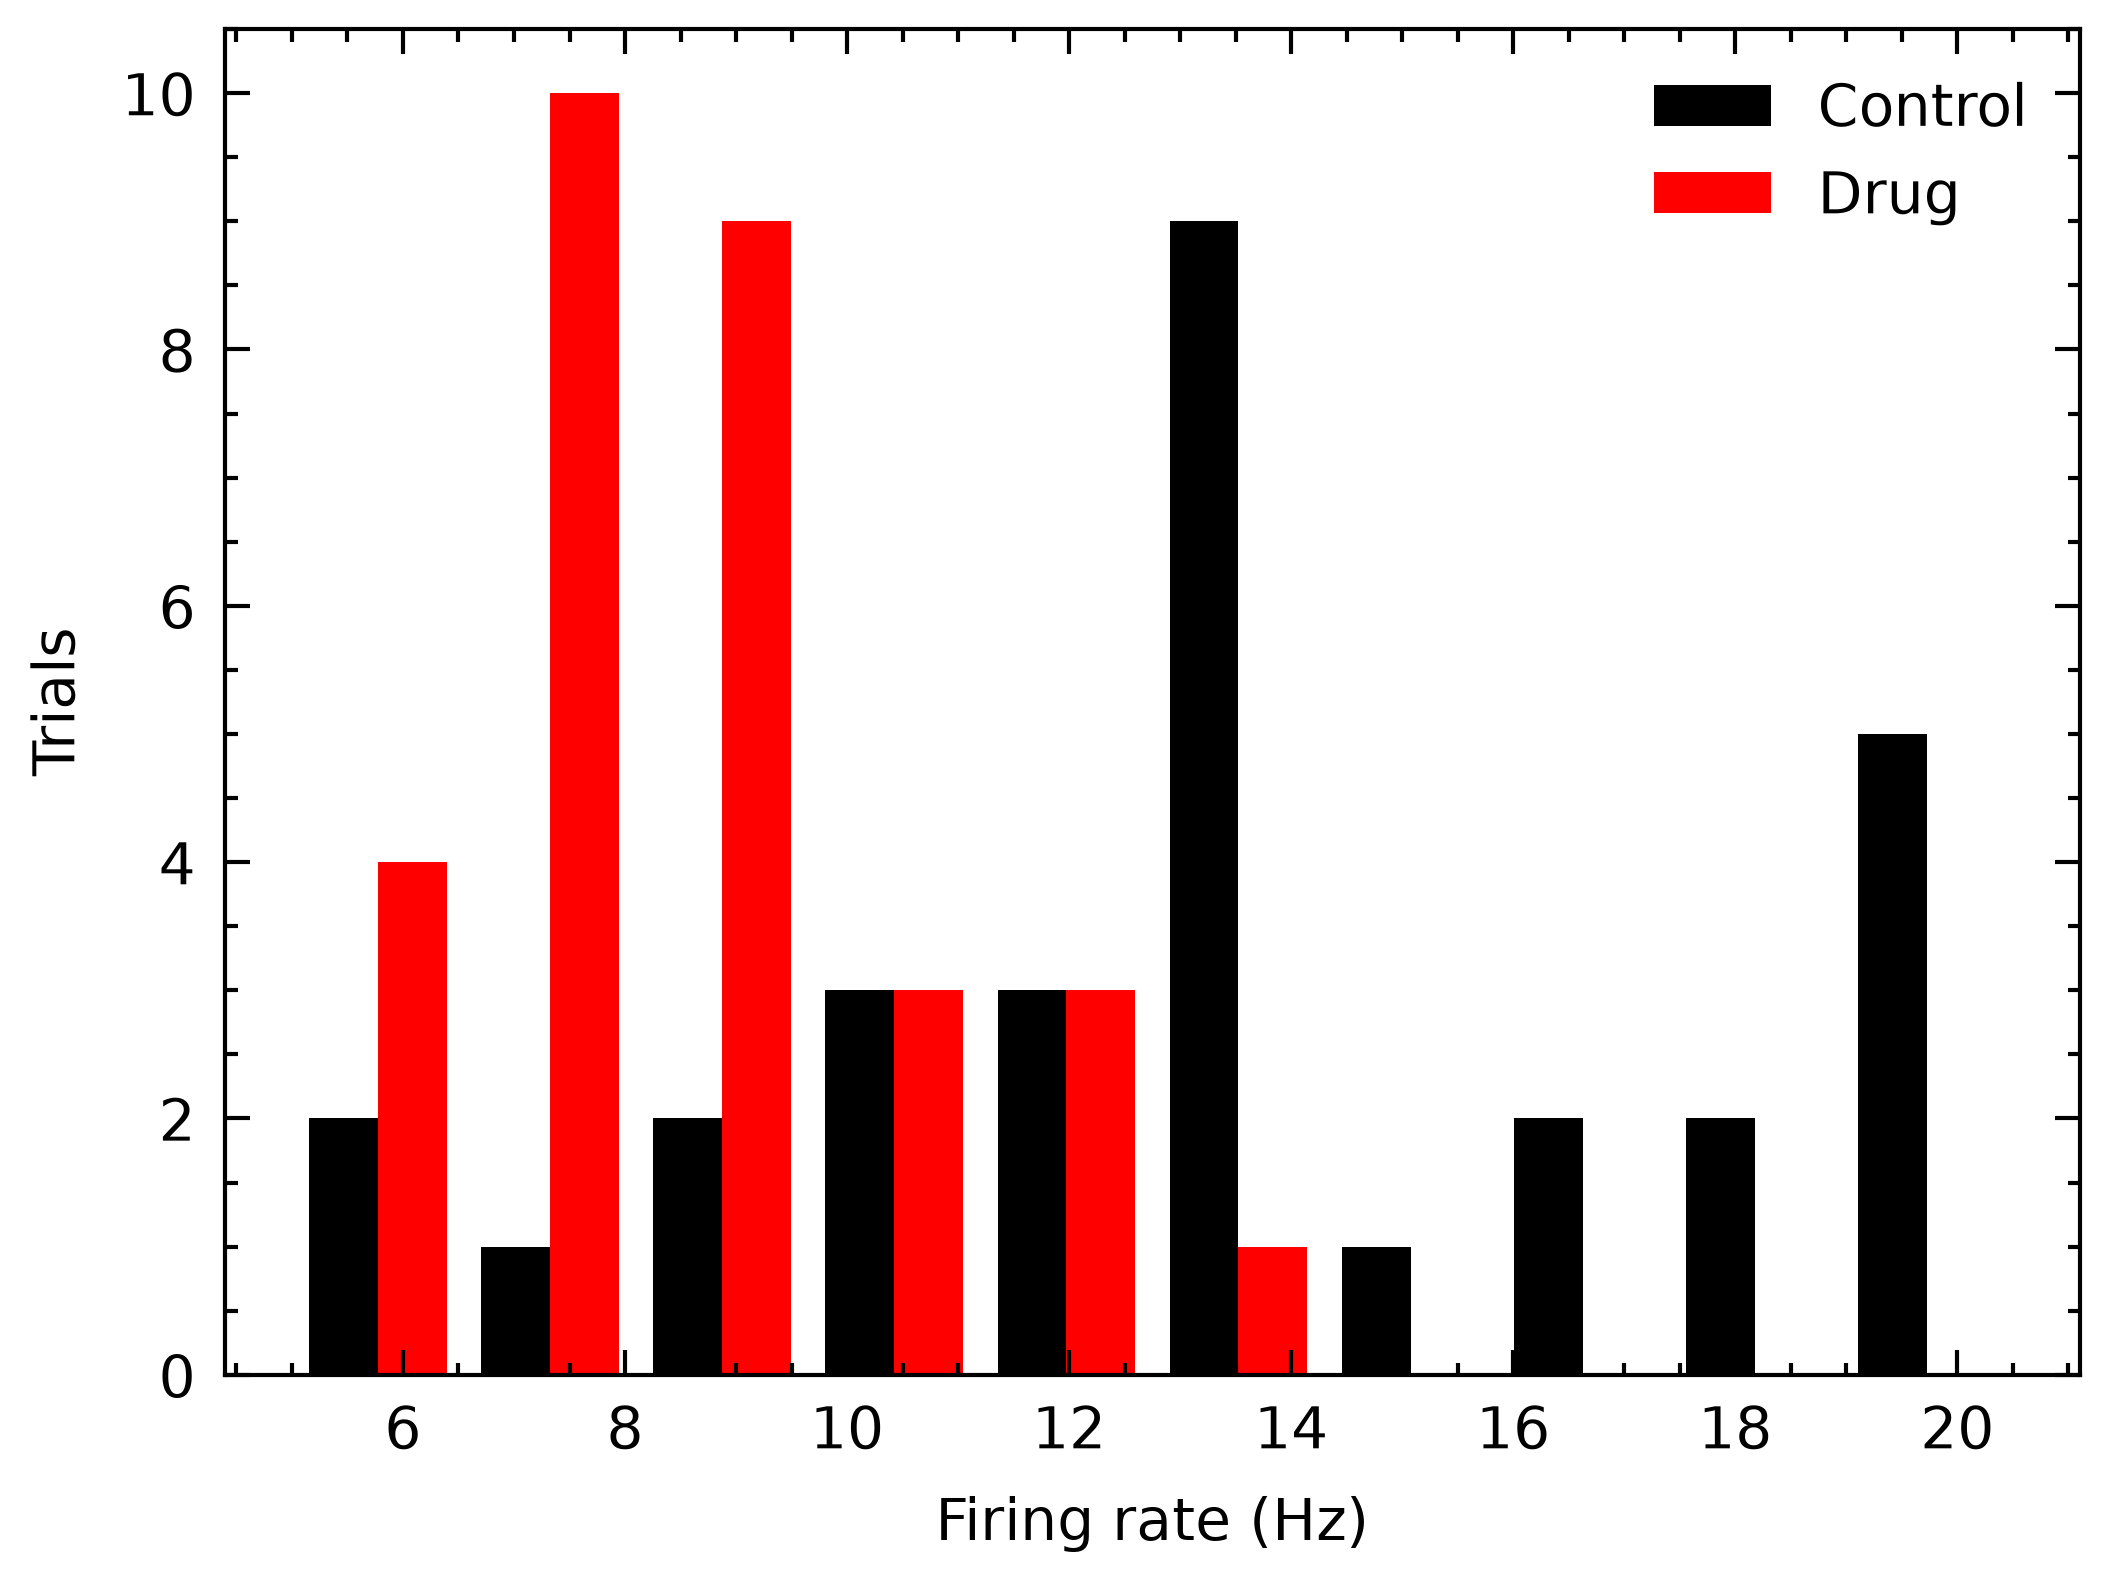

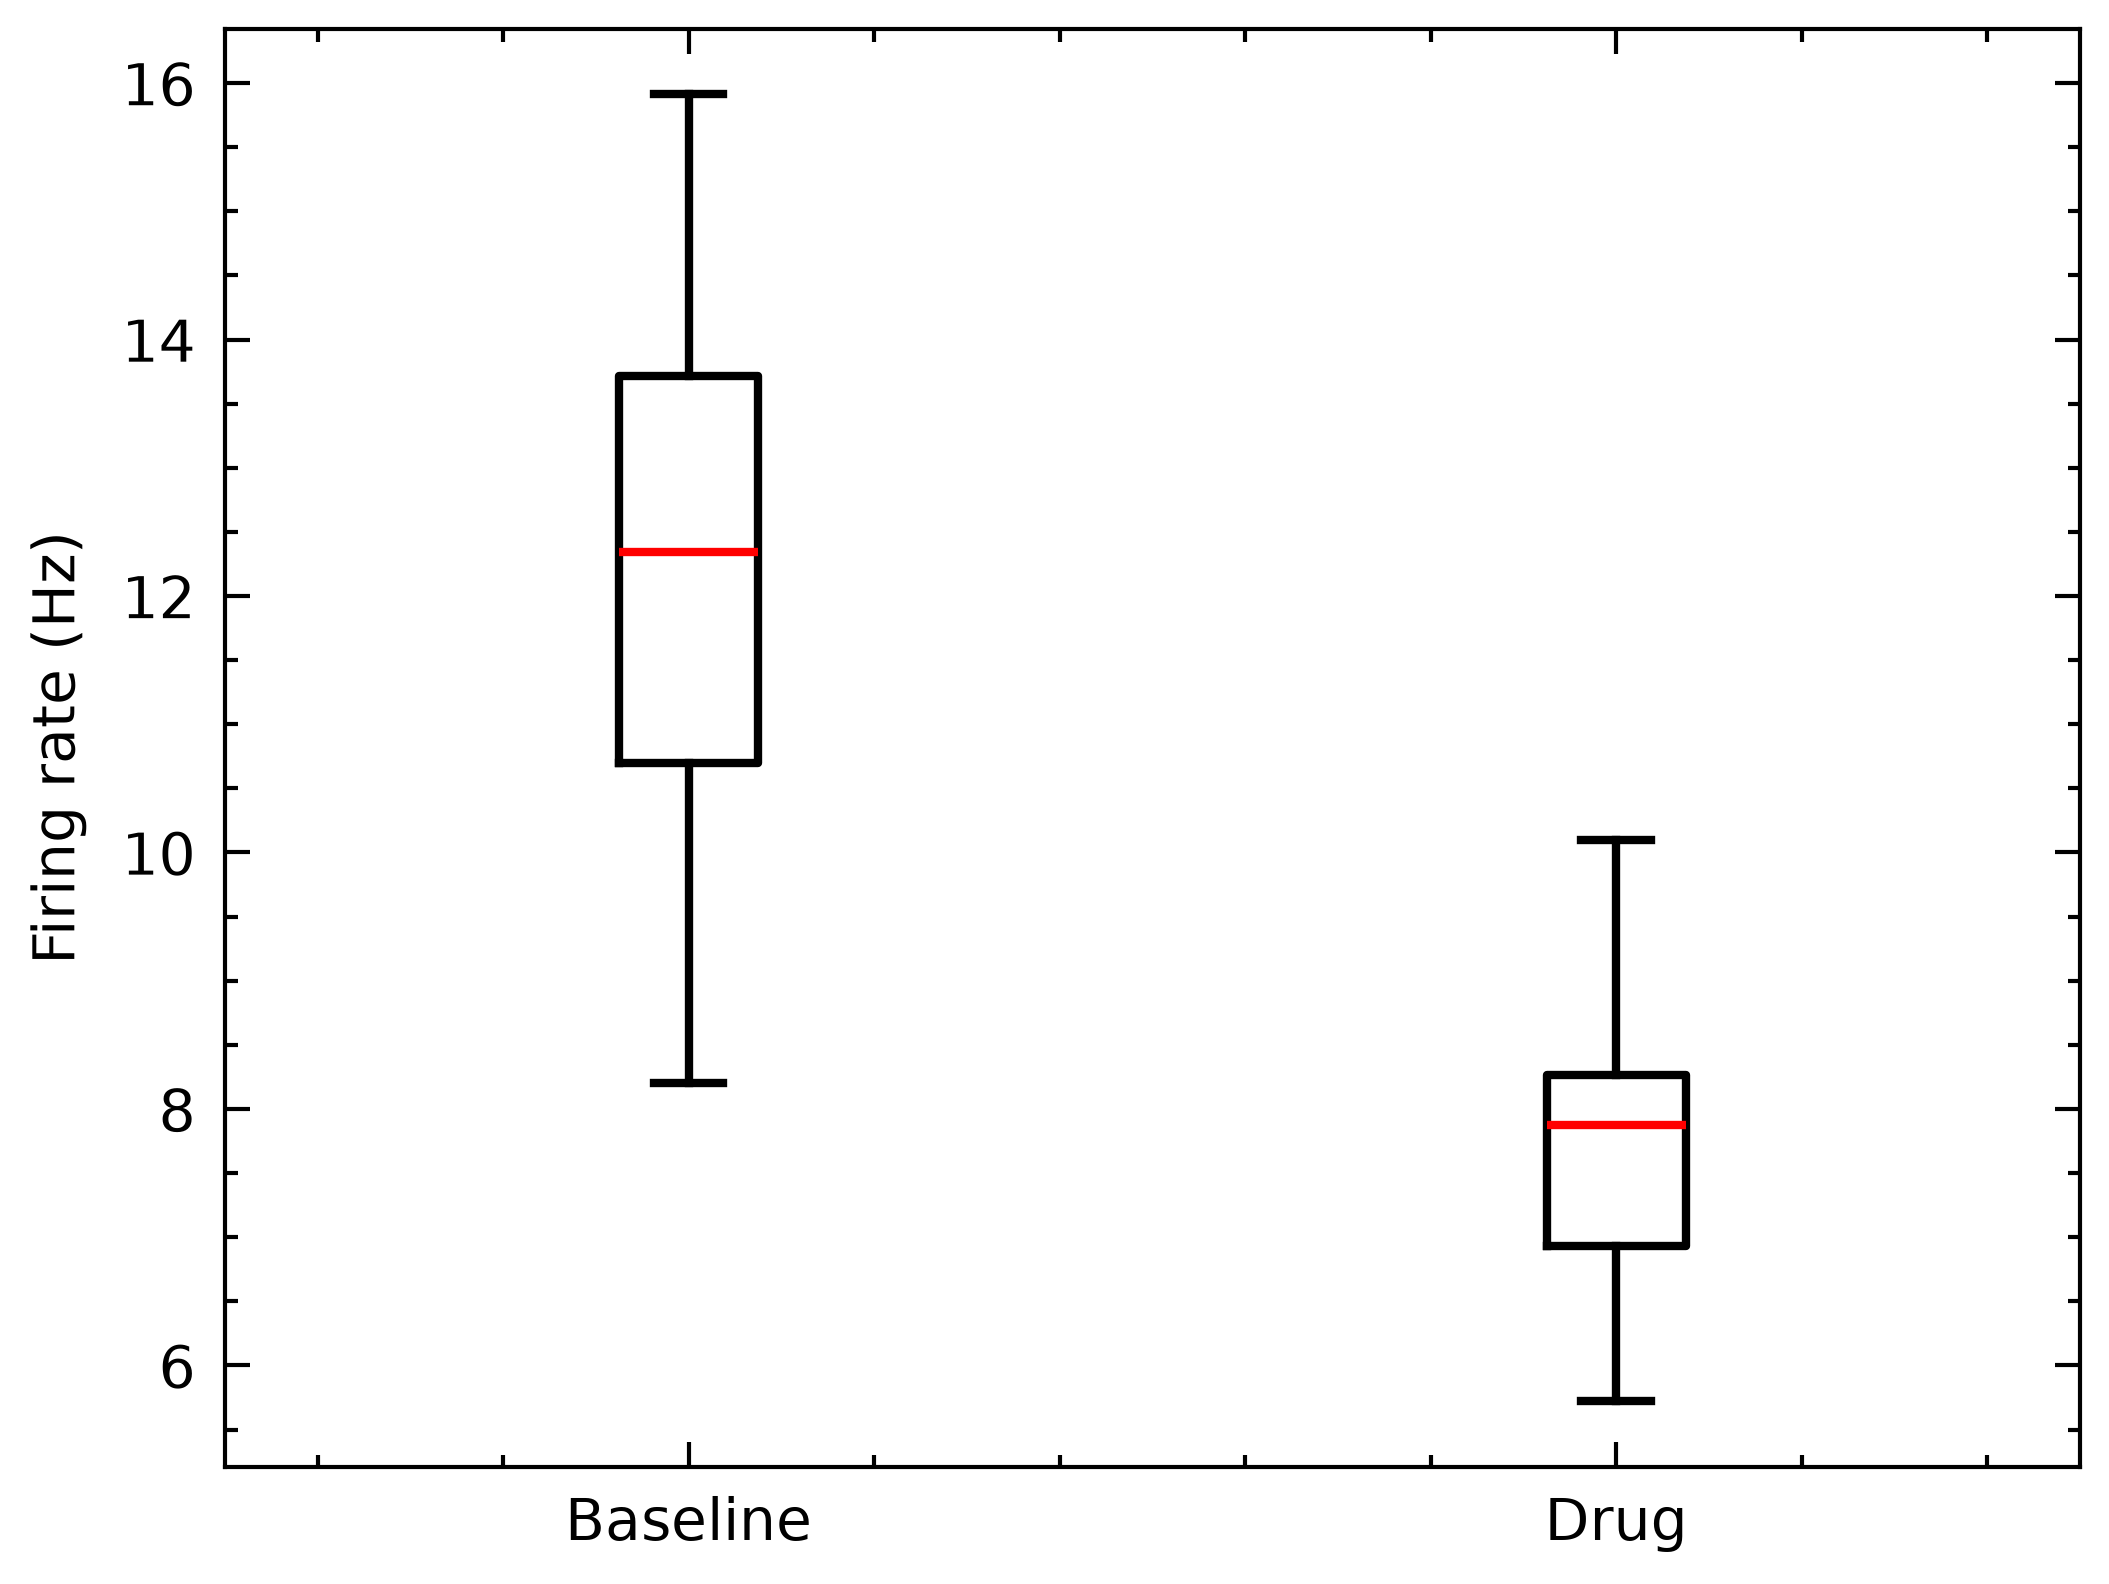

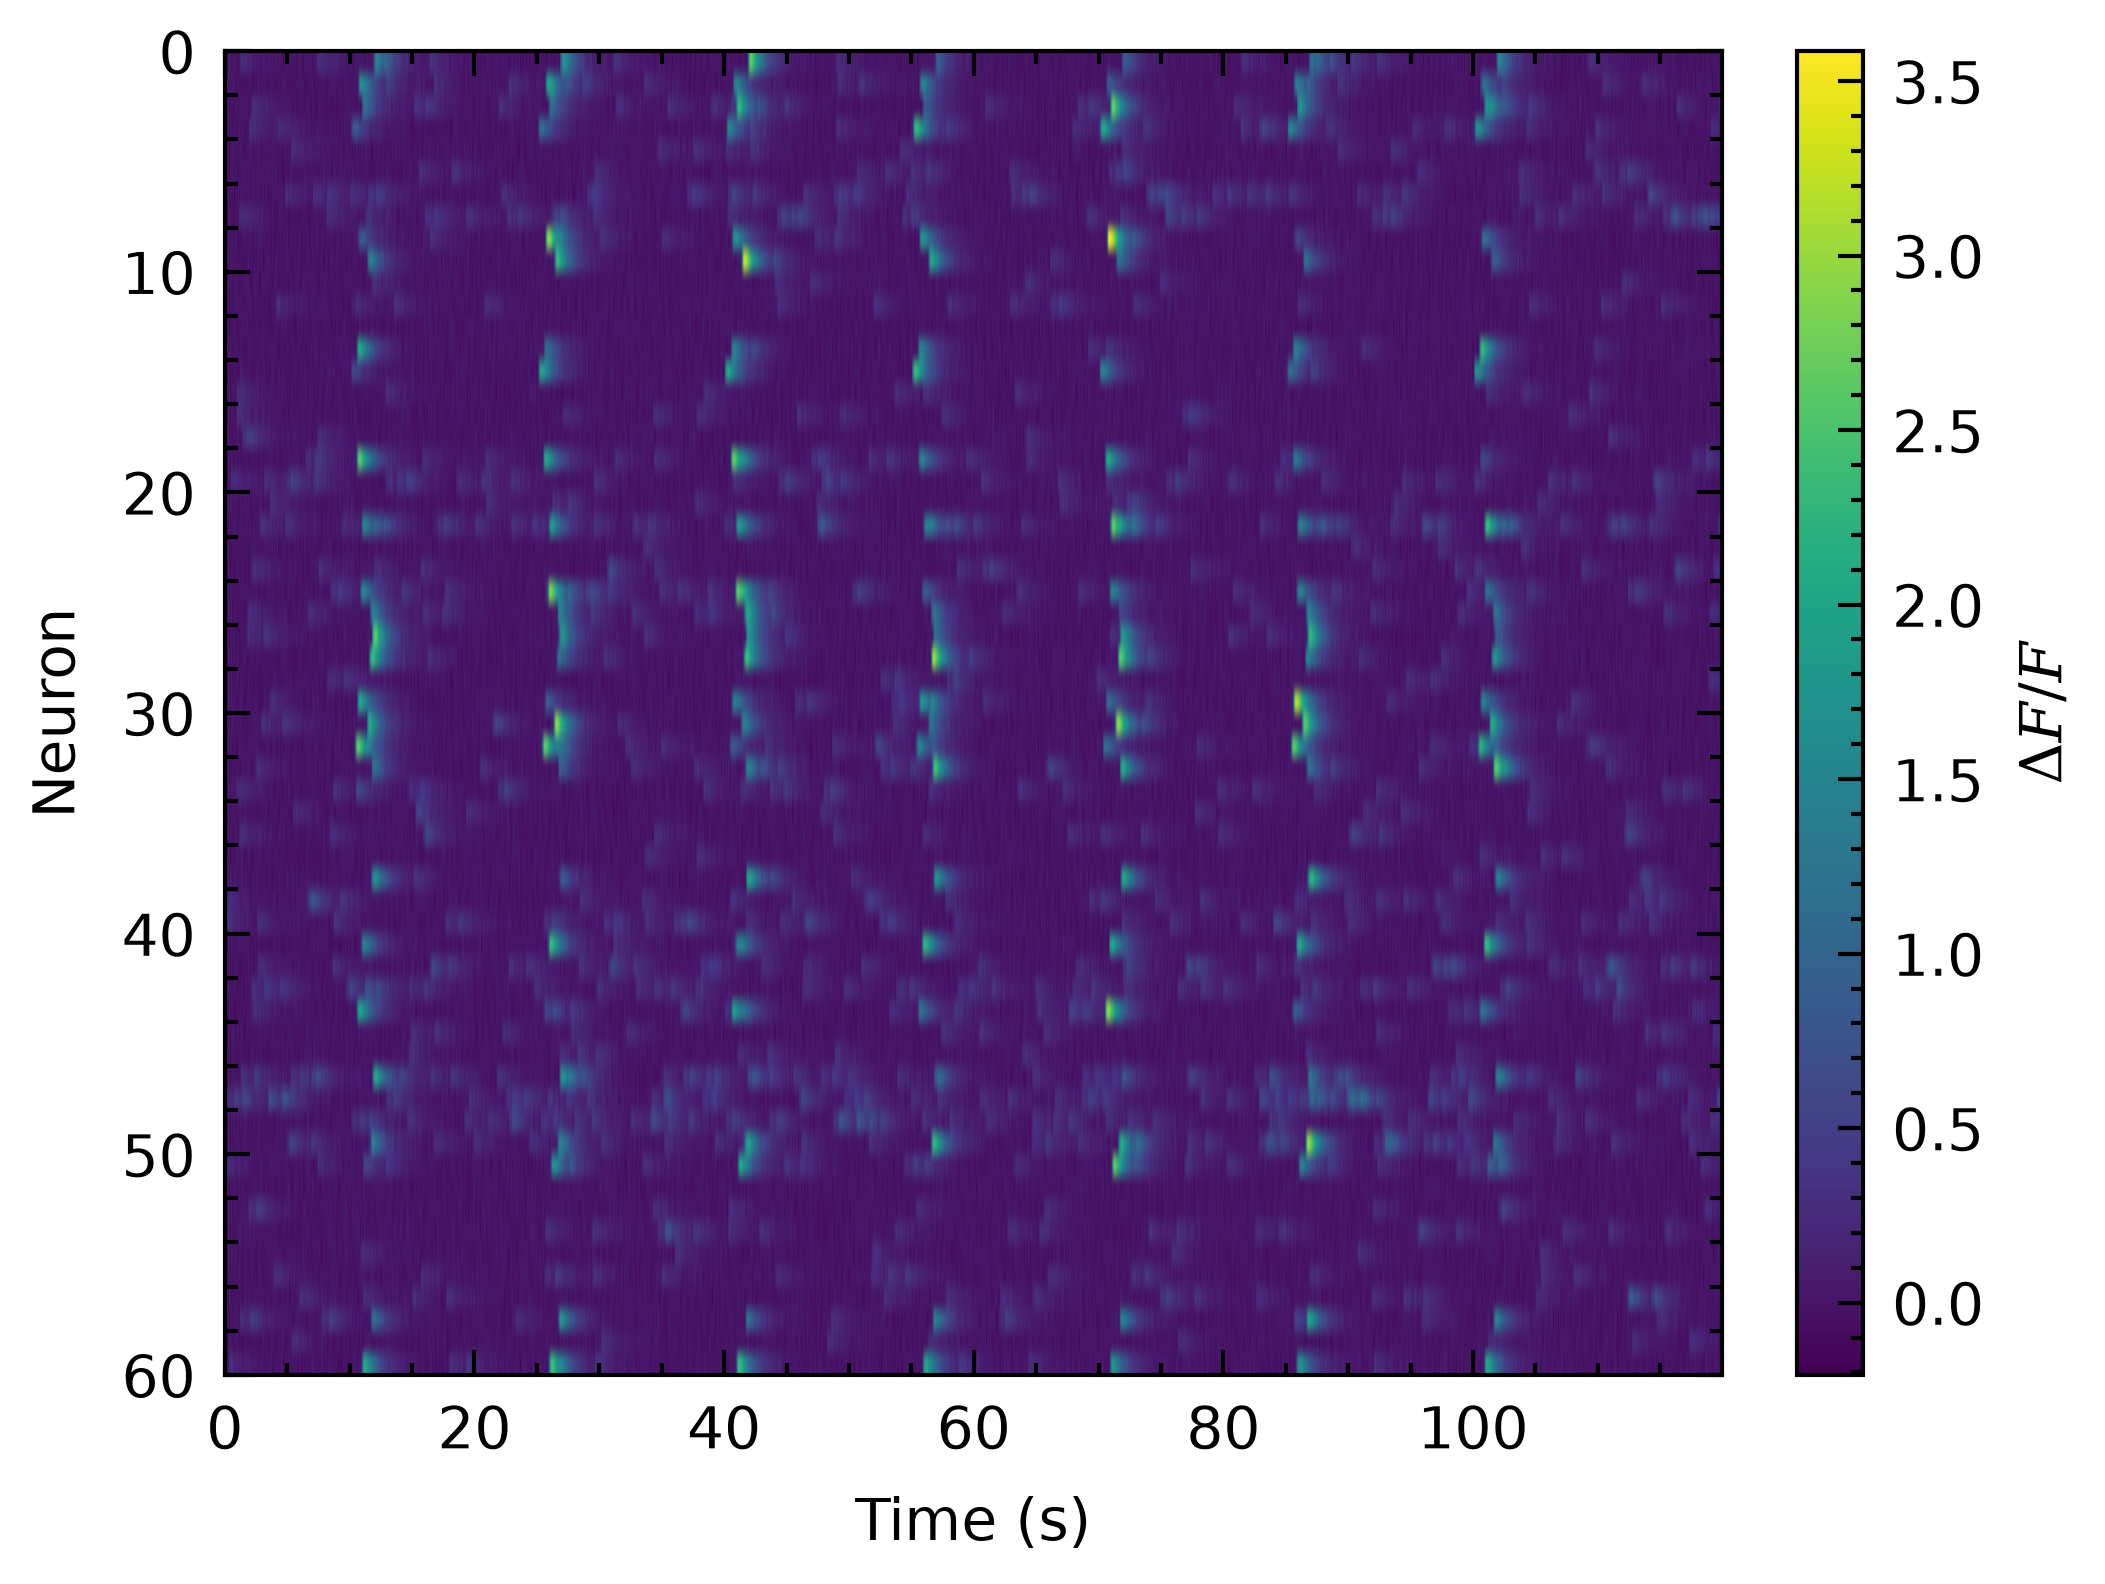

In [19]:
plt.style.use(["my_style.mplstyle"])
show_plots()

Some lines to add to the file:

| Add this line | What it does |
|---|---|
| `axes.grid: True` | a grid behind the data |
| `grid.color: 0.9` | ...in light grey |
| `patch.force_edgecolor: True` | outlines around histogram bars |
| `axes.titlelocation: left` | panel titles on the left, as in most papers |
| `figure.facecolor: EEEEEE` | grey background around the plot |
| `errorbar.capsize: 2` | little caps on the error bars |
| `hist.bins: 20` | more bins in every histogram |
| `boxplot.medianprops.color: black` | black median line in box plots |
| `boxplot.patchartist: True` | filled boxes |
| `image.cmap: magma` | another colormap for heatmaps |
| `image.aspect: auto` | heatmap fills the whole panel |

* A misspelled name only prints a warning and is ignored. The full list of names:
  `print(plt.rcParams.keys())`.
* The grey diagonal stayed grey: **anything set in the code wins over the style.**
* Styles stack: `plt.style.use(["my_style.mplstyle", "talk.mplstyle"])` applies the second on top of the first.

### Exercise (if you have time)
Make `my_style.mplstyle` look like the hand-styled plots you liked best in section 1. Then find your target
journal's column width and change `figure.figsize`.